<a href="https://colab.research.google.com/github/SMunganyinka/cassava-disease-classification/blob/main/cassava_leaf_disease_classification_improved.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Cassava Leaf Disease Classification: Handcrafted-Feature ML vs Deep Learning

**Course:** Introduction to Machine Learning – Summative Project  
**Author:** Shakira Munganyinka  
**GitHub:** _link_ · **Google Drive** (raw data zip + saved models): _link_ · **Demo video:** _link_

**Notebook map:** 1 Setup → 2 Problem & dataset → 3 Loading, caching & EDA → 4 Feature engineering → 5 Splits → 6 Traditional ML → 7 Deep learning (`tf.data`) → 8 Hybrid → 9 Experiment table → 10 Evaluation & error analysis → 11 Final test & saved models → 12 Conclusions.

### How this notebook maps to the project requirements
| Requirement | Where to find it |
|---|---|
| Problem, dataset, mission alignment | Section 2 (problem, source, why cassava in Rwanda/East Africa); Section 3 (21,397 raw images, class balance, sample photos) |
| Preprocessing and feature engineering | Section 3.1 (resizing, duplicate check), Section 4 (385 handcrafted features in 6 groups + data-quality and ANOVA analysis), Section 5 (stratified split, scalers fitted on train only) |
| Two paradigms, 7+ systematic experiments | Section 6 (ML-01 to ML-08), Section 7 (DL-01 to DL-06, DL-RS-01/02), Section 8 (HYB-01/02) = 18 experiments |
| Experiment table with settings, splits, metrics, observations, logs | Section 9 (Table I, `experiment_table.csv`, `report_table_I.csv`, W&B offline and TensorBoard logs) |
| Learning curves, confusion matrices, ROC/PR, bias–variance, error analysis | Section 10 (validation set) and Section 11 (test set, evaluated once) |
| Trade-offs (accuracy vs cost vs model size) | Section 9, trade-off table and plot |
| Reproducibility | Install cell, version printout, fixed seeds (`SEED = 42`), cached images/features, models saved to Drive |

Experiment IDs (ML-xx, DL-xx, HYB-xx) are the same IDs used in Table I of the written report.

## 1. Setup and configuration
All dependencies are in `requirements.txt`. Seeds are fixed for Python, NumPy and TensorFlow, and Weights & Biases runs in **offline mode** (logs in `artifacts/wandb`) so each row of the experiment table is traceable to a logged run. TensorBoard logs go to `artifacts/tensorboard`.

Outputs (results tables, cached features, logs and saved models) are written to **Google Drive** when `USE_DRIVE = True` in the persistence cell below, so they survive a Colab runtime reset. Run the cells **top to bottom**: install → config → Drive → Kaggle credentials → data → features → split → experiments → evaluation.

In [1]:
# Extra packages needed on Colab (TensorFlow, scikit-learn, pandas, numpy and matplotlib are preinstalled).
# For a local run use: pip install -r requirements.txt
!pip install -q wandb scikit-image kaggle

In [2]:
# !pip install -q wandb scikit-learn scikit-image pillow pandas numpy matplotlib seaborn joblib kaggle tensorflow
import os, time, json, random, warnings, zipfile, subprocess
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from joblib import Parallel, delayed
from PIL import Image
from IPython.display import display

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV, learning_curve
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, precision_score, recall_score,
                             roc_auc_score, average_precision_score, confusion_matrix, classification_report,
                             roc_curve, precision_recall_curve, auc)
from skimage.color import rgb2hsv, rgb2gray
from skimage.feature import hog, local_binary_pattern, graycomatrix, graycoprops

try:
    import tensorflow as tf
    from tensorflow import keras
    from tensorflow.keras import layers
    TF_OK = True
except ImportError:
    TF_OK = False
    print("TensorFlow not found - deep learning sections will be skipped.")

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RESAMPLE = getattr(Image, "Resampling", Image)

# ------------------------------ configuration ------------------------------
SEED = 42
QUICK_RUN = False                 # True = smoke test, False = full experiments for the report
IMG_SIZE = 224                    # cached image size (CNN input)
FEAT_SIZE = 128                   # size used for handcrafted feature extraction
DATA_DIR = Path(os.environ.get("CASSAVA_DIR", "data/cassava"))
RAW_IMG_DIR = DATA_DIR / "train_images"
CACHE_DIR = Path("data/cassava_cache") / str(IMG_SIZE)
ARTIFACT_DIR = Path("artifacts")
for d in (CACHE_DIR, ARTIFACT_DIR): d.mkdir(parents=True, exist_ok=True)
WANDB_PROJECT = "cassava-leaf-disease"
CLASS_NAMES = ["CBB", "CBSD", "CGM", "CMD", "Healthy"]    # label ids 0..4
CLASS_FULL = ["Cassava Bacterial Blight", "Cassava Brown Streak Disease", "Cassava Green Mottle",
              "Cassava Mosaic Disease", "Healthy"]
N_CLASSES = len(CLASS_NAMES)

os.environ["WANDB_MODE"] = "offline"; os.environ["WANDB_SILENT"] = "true"
try:
    import wandb; WANDB_OK = True
except ImportError:
    WANDB_OK = False
    print("wandb not installed - run `pip install wandb` to get offline run logs.")

def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); os.environ["PYTHONHASHSEED"] = str(seed)
    if TF_OK: tf.keras.utils.set_random_seed(seed)
set_seed()
print("QUICK_RUN =", QUICK_RUN, "| GPU:", tf.config.list_physical_devices("GPU") if TF_OK else "n/a")

QUICK_RUN = False | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


**Persistence and environment.**

In [3]:
# Persist outputs on Google Drive so results, caches and models survive a Colab runtime reset.
# Set USE_DRIVE = False to keep everything on the local disk instead.
USE_DRIVE = True
if USE_DRIVE:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        PROJECT_DIR = Path("/content/drive/MyDrive/cassava_project")
        ARTIFACT_DIR = PROJECT_DIR / "artifacts"
        CACHE_DIR = PROJECT_DIR / "cache" / str(IMG_SIZE)
    except Exception as e:
        print("Google Drive not available - using local folders instead:", e)
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True); CACHE_DIR.mkdir(parents=True, exist_ok=True)
print("Artifacts folder:", ARTIFACT_DIR); print("Image cache folder:", CACHE_DIR)

Mounted at /content/drive
Artifacts folder: /content/drive/MyDrive/cassava_project/artifacts
Image cache folder: /content/drive/MyDrive/cassava_project/cache/224


In [4]:
# Environment record for reproducibility
import sys, platform, sklearn, skimage
print("Python", sys.version.split()[0], "|", platform.platform())
for name, mod in [("numpy", np), ("pandas", pd), ("scikit-learn", sklearn), ("scikit-image", skimage)]:
    print(f"{name}: {mod.__version__}")
if TF_OK: print("tensorflow:", tf.__version__, "| GPUs:", tf.config.list_physical_devices("GPU"))
if WANDB_OK: print("wandb:", wandb.__version__)
print("Seed:", SEED, "| QUICK_RUN:", QUICK_RUN)

Python 3.13.15 | Linux-6.6.122+-x86_64-with-glibc2.39
numpy: 2.1.3
pandas: 2.2.3
scikit-learn: 1.6.1
scikit-image: 0.25.2
tensorflow: 2.21.0 | GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
wandb: 0.28.1
Seed: 42 | QUICK_RUN: False


**Kaggle credentials (Colab).** First upload your `kaggle.json` token (cell 1), then copy it to `~/.kaggle` and install the Kaggle CLI (cell 2). The dataset cell in Section 3 needs this to download the competition data.

In [10]:
import os, glob
# Find the file wherever it actually ended up
candidates = ['/root/.kaggle/kaggle.json', '/content/kaggle.json', 'kaggle.json']
src = next((p for p in candidates if os.path.exists(p)), None)
print("Found kaggle.json at:", src)

os.makedirs('/root/.kaggle', exist_ok=True)
if src != '/root/.kaggle/kaggle.json':
    import shutil
    shutil.copy(src, '/root/.kaggle/kaggle.json')
os.chmod('/root/.kaggle/kaggle.json', 0o600)
print("Ready:", os.popen('ls -la /root/.kaggle/').read())

Found kaggle.json at: /root/.kaggle/kaggle.json
Ready: total 16
drwxr-xr-x 2 root root 4096 Oct 20 17:21 .
drwx------ 1 root root 4096 Oct 20 17:19 ..
-rw------- 1 root root   74 Oct 20 17:21 kaggle.json



In [7]:
import subprocess
r = subprocess.run(['kaggle', 'competitions', 'list', '-s', 'cassava'],
                   capture_output=True, text=True)
print(r.stdout)
print("STDERR:", r.stderr)

You must authenticate before you can call the Kaggle API.
Follow the instructions to authenticate at: https://github.com/Kaggle/kaggle-cli/blob/main/docs/README.md#authentication

STDERR: 


In [9]:
import os
import shutil
from pathlib import Path

# Confirm that kaggle.json exists
assert Path("/content/kaggle.json").exists(), (
    "Please upload kaggle.json using files.upload() first."
)

# Configure Kaggle credentials
Path("/root/.kaggle").mkdir(parents=True, exist_ok=True)
shutil.copy(
    "/content/kaggle.json",
    "/root/.kaggle/kaggle.json"
)
os.chmod("/root/.kaggle/kaggle.json", 0o600)

# Install Kaggle CLI
!pip install -q kaggle

print("Kaggle CLI configured.")

Kaggle CLI configured.


## 2. Problem definition, dataset and mission alignment

**Problem.** Cassava is a common food and income crop for hundreds of millions of people in sub-Saharan Africa, and viral and bacterial diseases can destroy entire harvests. Smallholder farmers rarely have access to an expert who can diagnose a leaf in time. The task is to classify a photograph of a cassava leaf into one of **five classes**: Cassava Bacterial Blight (CBB), Cassava Brown Streak Disease (CBSD), Cassava Green Mottle (CGM), Cassava Mosaic Disease (CMD) or Healthy. A reliable phone-camera classifier could support extension officers and farmers (relevant to my own context in Rwanda).

**Dataset.** Cassava Leaf Disease Classification (Kaggle competition data from the Makerere AI Lab / NaCRRI, Uganda; descends from the iCassava challenge, Mwebaze et al., 2019). It holds **21,397 labelled field photographs** taken by farmers, so it is real, open, imbalanced (CMD ≈ 61 %) and noisy, with varied lighting, backgrounds and some mislabelled images. It is not a built-in or synthetic dataset. Source: https://www.kaggle.com/competitions/cassava-leaf-disease-classification

**Two modelling paradigms compared**
1. **Traditional ML (scikit-learn)** on *handcrafted* features I engineer from the pixels (colour statistics, HSV histograms, symptom-colour fractions, LBP/GLCM texture, HOG shape).
2. **Deep learning (TensorFlow/Keras)** CNNs trained end-to-end: a small CNN from scratch and transfer learning (MobileNetV2, EfficientNetB0), fed with `tf.data` pipelines.
3. A **hybrid** run (frozen CNN embeddings + classical classifier) as an extra comparison.

**Data-quality rules adopted:** exact/near-duplicate images are removed with a perceptual difference hash; duplicates with *conflicting* labels are dropped entirely; the test set is touched only once.



## 3. Data loading, image caching and exploratory analysis
 The below cell downloads the zip and extracts only `train.csv`, the label map and `train_images/`. If it fails, download the zip manually and extract those three items into `DATA_DIR`.

In [11]:
def ensure_dataset():
    if (DATA_DIR / "train.csv").exists() and RAW_IMG_DIR.exists():
        print("Dataset already present in", DATA_DIR); return
    DATA_DIR.mkdir(parents=True, exist_ok=True)
    zip_path = DATA_DIR / "cassava-leaf-disease-classification.zip"
    if not zip_path.exists():
        print("Downloading with the Kaggle CLI (several GB) ...")
        r = subprocess.run(["kaggle", "competitions", "download", "-c", "cassava-leaf-disease-classification",
                            "-p", str(DATA_DIR)], capture_output=True, text=True)
        if r.returncode != 0:
            raise RuntimeError("Kaggle download failed. Accept the competition rules, set up kaggle.json, or "
                               f"download manually into {DATA_DIR}.\n{r.stderr[-400:]}")
    with zipfile.ZipFile(zip_path) as z:
        wanted = [n for n in z.namelist() if n.startswith("train_images/") or n in
                  ("train.csv", "label_num_to_disease_map.json")]
        z.extractall(DATA_DIR, members=wanted)
    print("Extracted", len(wanted), "files to", DATA_DIR)

ensure_dataset()
labels_df = pd.read_csv(DATA_DIR / "train.csv")                    # columns: image_id, label
print(f"Raw dataset: {len(labels_df):,} images -> "
      f"{'meets' if len(labels_df) >= 20000 else 'DOES NOT meet'} the 20,000-sample requirement")
map_file = DATA_DIR / "label_num_to_disease_map.json"
if map_file.exists():
    print("Label map in data:", json.load(open(map_file)), "| notebook assumes:", dict(enumerate(CLASS_FULL)))
raw_n = len(labels_df)
if QUICK_RUN:
    labels_df = labels_df.sample(2500, random_state=SEED).reset_index(drop=True)
    print("QUICK_RUN: using", len(labels_df), "images")

Extracted 21399 files to data/cassava
Raw dataset: 21,397 images -> meets the 20,000-sample requirement
Label map in data: {'0': 'Cassava Bacterial Blight (CBB)', '1': 'Cassava Brown Streak Disease (CBSD)', '2': 'Cassava Green Mottle (CGM)', '3': 'Cassava Mosaic Disease (CMD)', '4': 'Healthy'} | notebook assumes: {0: 'Cassava Bacterial Blight', 1: 'Cassava Brown Streak Disease', 2: 'Cassava Green Mottle', 3: 'Cassava Mosaic Disease', 4: 'Healthy'}


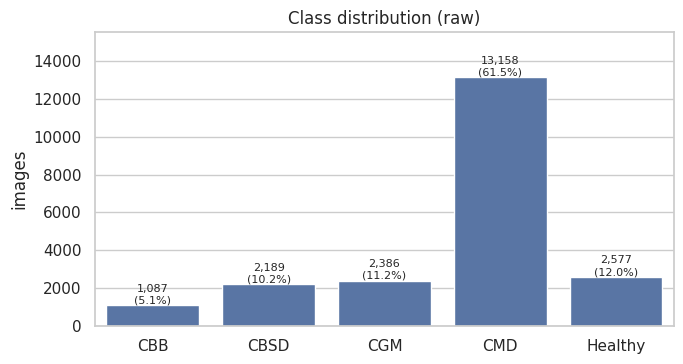

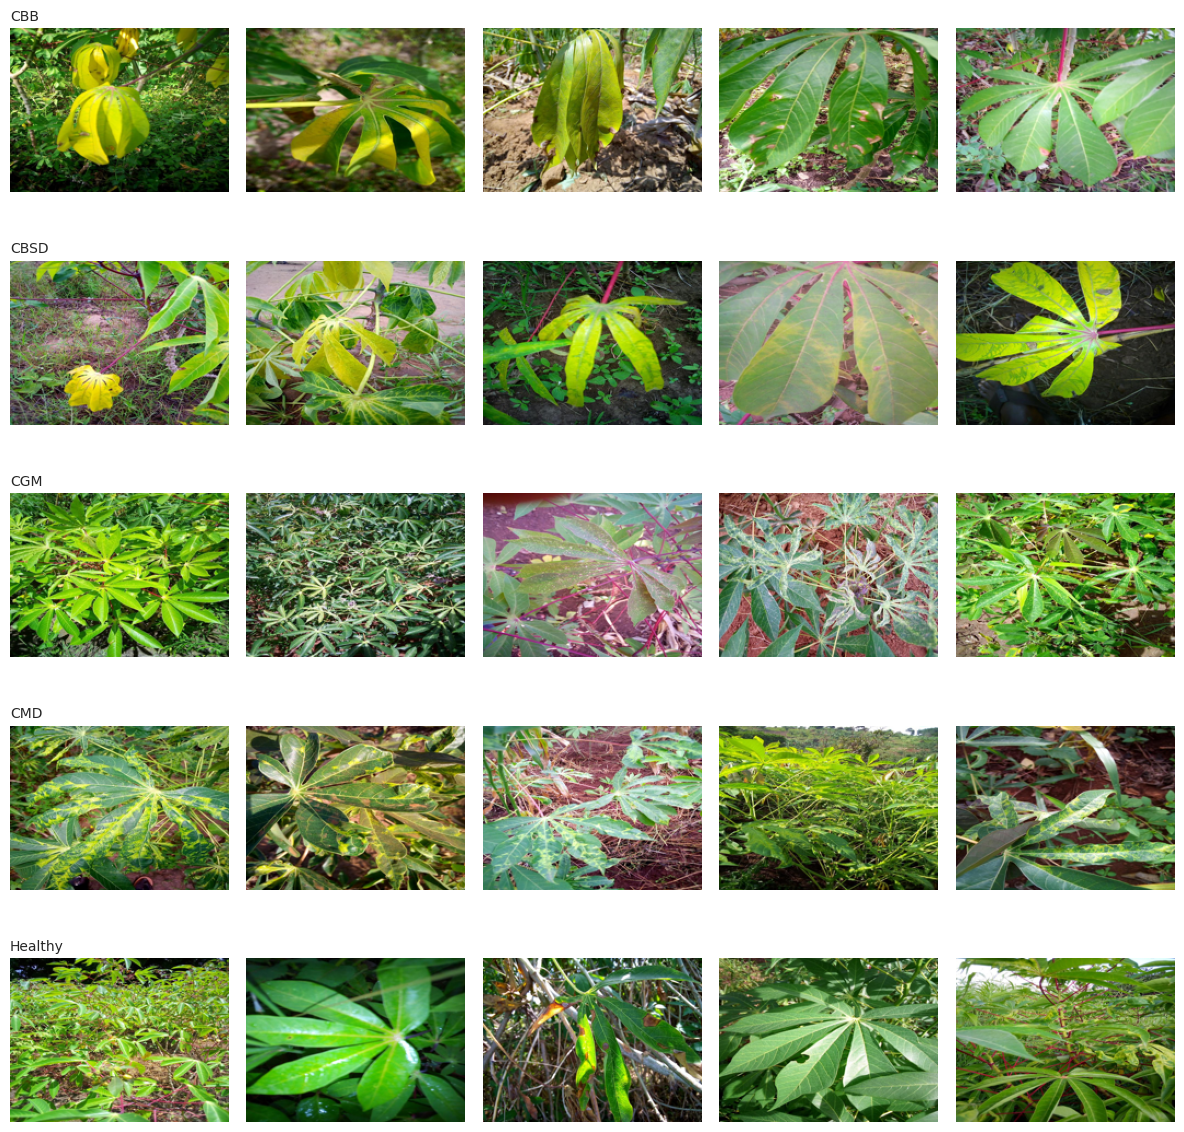

Image sizes (sample of 300): [((800, 600), 300)]


In [12]:
fig, ax = plt.subplots(figsize=(7, 3.8))
cnt = labels_df["label"].value_counts().sort_index()
sns.barplot(x=[CLASS_NAMES[i] for i in cnt.index], y=cnt.values, ax=ax)
for i, v in enumerate(cnt.values): ax.text(i, v, f"{v:,}\n({v/len(labels_df):.1%})", ha="center", va="bottom", fontsize=8)
ax.set_title("Class distribution (raw)"); ax.set_ylabel("images"); ax.set_ylim(0, cnt.max() * 1.18)
plt.tight_layout(); plt.show()

# sample gallery (one row per class) + image-size check
fig, axes = plt.subplots(N_CLASSES, 5, figsize=(12, 2.4 * N_CLASSES))
for c in range(N_CLASSES):
    ids = labels_df[labels_df.label == c].sample(5, random_state=SEED).image_id
    for j, i in enumerate(ids):
        with Image.open(RAW_IMG_DIR / i) as im: axes[c, j].imshow(im.convert("RGB").resize((200, 150)))
        axes[c, j].axis("off")
    axes[c, 0].set_title(CLASS_NAMES[c], loc="left", fontsize=10)
plt.tight_layout(); plt.show()
sizes = Counter(Image.open(RAW_IMG_DIR / i).size for i in labels_df.image_id.sample(min(300, len(labels_df)), random_state=SEED))
print("Image sizes (sample of 300):", sizes.most_common(3))

The dataset has class imbalance, meaning some cassava disease classes like CMD have more images than others. Accuracy alone can be misleading because a model may perform well on the larger classes but poorly on smaller ones. Therefore, I use macro-F1 and balanced accuracy to measure performance across all classes. Each class has different visual symptoms, such as spots, yellowing, mosaic patterns, or damaged leaves. Field photos are also harder to classify because they may contain hands, soil, shadows, and several leaves in one image. This makes the task more difficult than using controlled lab images, such as PlantVillage.

### 3.1 Image caching and de-duplication
Every image is resized **once** to `IMG_SIZE × IMG_SIZE` and cached as JPEG (so training does not repeatedly decode large 800×600 photos). While doing so a 256-bit perceptual **difference hash** is computed to find duplicates. Duplicate groups with conflicting labels are dropped; consistent duplicates keep one copy.

In [13]:
def dhash(img, size=16):
    g = img.convert("L").resize((size + 1, size), RESAMPLE.LANCZOS)
    a = np.asarray(g, dtype=np.int16)
    return np.packbits((a[:, 1:] > a[:, :-1]).flatten()).tobytes().hex()

def cache_one(image_id):
    try:
        with Image.open(RAW_IMG_DIR / image_id) as im:
            im = im.convert("RGB"); h = dhash(im); out = CACHE_DIR / image_id
            if not out.exists():
                im.resize((IMG_SIZE, IMG_SIZE), RESAMPLE.BILINEAR).save(out, quality=95)
        return h
    except Exception:
        return None

HASH_FILE = ARTIFACT_DIR / f"image_hashes_{IMG_SIZE}.csv"
known = pd.read_csv(HASH_FILE).set_index("image_id")["hash"].to_dict() if HASH_FILE.exists() else {}
todo = [i for i in labels_df.image_id if i not in known]
if todo:
    t0 = time.time()
    res = Parallel(n_jobs=-1, verbose=0)(delayed(cache_one)(i) for i in todo)
    known.update(dict(zip(todo, res)))
    pd.DataFrame({"image_id": list(known), "hash": list(known.values())}).to_csv(HASH_FILE, index=False)
    print(f"Resized/cached {len(todo):,} images in {time.time()-t0:.0f}s")

df = labels_df.assign(hash=labels_df.image_id.map(known))
n0 = len(df); df = df.dropna(subset=["hash"])
n_corrupt = n0 - len(df)
conflict = df.groupby("hash")["label"].nunique(); conflict = conflict[conflict > 1].index
n_conf = int(df["hash"].isin(conflict).sum()); df = df[~df["hash"].isin(conflict)]
n1 = len(df); df = df.drop_duplicates("hash").reset_index(drop=True)
print(f"Corrupt: {n_corrupt} | removed for conflicting duplicate labels: {n_conf} | "
      f"consistent duplicates removed: {n1 - len(df)} | final dataset: {len(df):,} images (raw: {raw_n:,})")
display(df["label"].map(dict(enumerate(CLASS_NAMES))).value_counts(normalize=True).round(3).to_frame("share"))

Corrupt: 0 | removed for conflicting duplicate labels: 0 | consistent duplicates removed: 0 | final dataset: 21,397 images (raw: 21,397)


,share
label,
CMD,0.615
Healthy,0.120
CGM,0.112
CBSD,0.102
CBB,0.051


**Result of the duplicate check.** No corrupt files, no conflicting-label duplicates and no exact duplicates were found among the 21,397 images, so the cleaned dataset equals the raw dataset. The 256-bit difference hash only catches near-identical copies of the same photo. Different photos of the same plant can still look very similar, so train/test similarity remains a possible limitation to mention in the report.

## 4. Feature engineering for the traditional models
Classical models cannot consume raw pixels sensibly, so features are **engineered from domain knowledge about how these diseases look**:

| Group | Features | Rationale |
|---|---|---|
| `rgb` | per-channel mean/std | overall colour and contrast |
| `hsv` | hue (16 bins), saturation (8), value (8) histograms + means | robust to lighting; yellowing (mosaic) shifts hue |
| `symptom` | excess-green index, fractions of green / yellow / brown / dark pixels | direct proxies for chlorosis and necrosis |
| `lbp` | uniform Local Binary Pattern histogram (10 bins) | fine leaf texture |
| `glcm` | contrast, homogeneity, energy, correlation (Grey-Level Co-occurrence) | mottling / blotchy texture |
| `hog` | Histogram of Oriented Gradients on a 64×64 grey image (324 dims) | leaf shape, vein and lesion edges |

Extraction runs in parallel on the cached images and is itself cached.

In [14]:
def extract_features(path):
    img = Image.open(path).convert("RGB").resize((FEAT_SIZE, FEAT_SIZE), RESAMPLE.BILINEAR)
    rgb = np.asarray(img, dtype=np.float32) / 255.0
    hsv = rgb2hsv(rgb); hch, sch, vch = hsv[..., 0], hsv[..., 1], hsv[..., 2]
    f = {}
    for i, c in enumerate("rgb"):
        f[f"rgb_{c}_mean"] = rgb[..., i].mean(); f[f"rgb_{c}_std"] = rgb[..., i].std()
    for name, ch, bins in (("h", hch, 16), ("s", sch, 8), ("v", vch, 8)):
        hist, _ = np.histogram(ch, bins=bins, range=(0, 1)); hist = hist / hist.sum()
        for k, val in enumerate(hist): f[f"hsv_{name}{k}"] = val
        f[f"hsv_{name}_mean"] = ch.mean()
    exg = 2 * rgb[..., 1] - rgb[..., 0] - rgb[..., 2]
    f["symptom_exg_mean"] = exg.mean(); f["symptom_exg_std"] = exg.std()
    f["symptom_frac_green"] = ((hch > 0.22) & (hch < 0.45) & (sch > 0.25)).mean()
    f["symptom_frac_yellow"] = ((hch > 0.11) & (hch <= 0.22) & (sch > 0.25) & (vch > 0.4)).mean()
    f["symptom_frac_brown"] = ((hch <= 0.11) & (sch > 0.25) & (vch < 0.6)).mean()
    f["symptom_frac_dark"] = (vch < 0.2).mean()
    gray = (rgb2gray(rgb) * 255).astype(np.uint8)
    lbp = local_binary_pattern(gray, 8, 1, "uniform")
    hist, _ = np.histogram(lbp, bins=10, range=(0, 10)); hist = hist / hist.sum()
    for k, val in enumerate(hist): f[f"lbp_{k}"] = val
    glcm = graycomatrix(gray // 8, distances=[1, 3], angles=[0, np.pi / 4, np.pi / 2, 3 * np.pi / 4],
                        levels=32, symmetric=True, normed=True)
    for prop in ("contrast", "homogeneity", "energy", "correlation"):
        f[f"glcm_{prop}"] = graycoprops(glcm, prop).mean()
    hg = hog(gray[::2, ::2], orientations=9, pixels_per_cell=(16, 16), cells_per_block=(2, 2), feature_vector=True)
    for k, val in enumerate(hg): f[f"hog_{k}"] = val
    return f

FEAT_FILE = ARTIFACT_DIR / f"handcrafted_features_{len(df)}.pkl"
if FEAT_FILE.exists():
    feats = pd.read_pickle(FEAT_FILE); print("Loaded cached features", feats.shape)
else:
    t0 = time.time()
    rows = Parallel(n_jobs=-1)(delayed(extract_features)(str(CACHE_DIR / i)) for i in df.image_id)
    feats = pd.DataFrame(rows); feats.to_pickle(FEAT_FILE)
    print(f"Extracted {feats.shape[1]} features for {len(feats):,} images in {time.time()-t0:.0f}s")

def group_of(c):
    for g in ("rgb", "hsv", "symptom", "lbp", "glcm", "hog"):
        if c.startswith(g + "_"): return g
FEATURE_GROUPS = {}
for c in feats.columns: FEATURE_GROUPS.setdefault(group_of(c), []).append(c)
print({g: len(v) for g, v in FEATURE_GROUPS.items()})
assert not feats.isna().any().any(), "NaNs in features"

Loaded cached features (21397, 385)
{'rgb': 6, 'hsv': 35, 'symptom': 6, 'lbp': 10, 'glcm': 4, 'hog': 324}


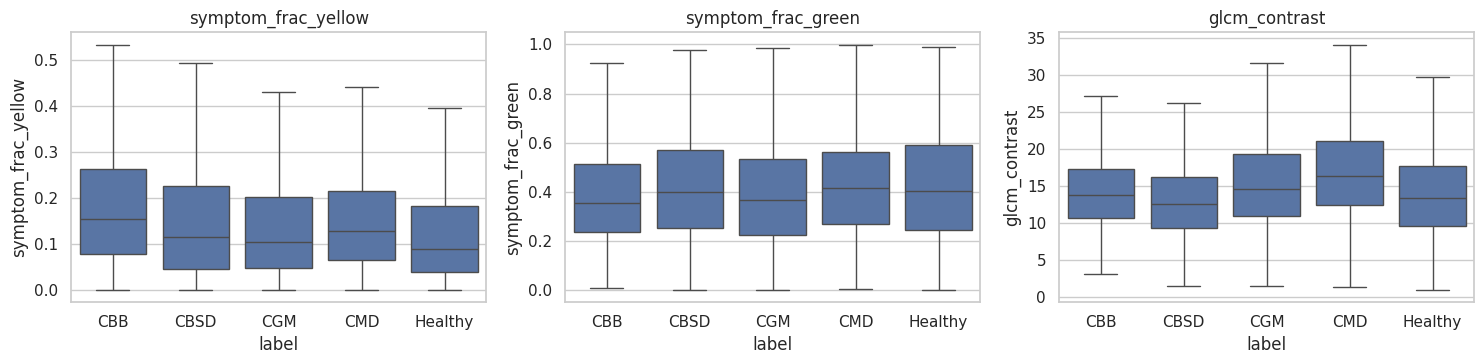

In [15]:
# Do the engineered symptom features separate the classes?
show = feats.assign(label=df["label"].map(dict(enumerate(CLASS_NAMES))).values)
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
for a_, col in zip(ax, ["symptom_frac_yellow", "symptom_frac_green", "glcm_contrast"]):
    sns.boxplot(data=show, x="label", y=col, order=CLASS_NAMES, ax=a_, showfliers=False); a_.set_title(col)
plt.tight_layout(); plt.show()

Some features differ between classes, such as yellowing in Cassava Mosaic Disease. Other classes may show spots, brown areas, or damaged leaf edges. However, some symptoms look similar across different diseases, so their features can overlap. This may cause classical machine learning models to confuse classes with similar visual symptoms.

## 5. Train / validation / test split
A **70 / 15 / 15 stratified split** (14,977 / 3,210 / 3,210 images) that preserves class proportions (CMD is about 61.5 % in every split). The validation set is used for all model selection; the **test set is used once** at the end. Duplicates were checked before splitting (Section 3.1), so identical images cannot appear in two splits. Scalers (and PCA) live inside scikit-learn pipelines and are fitted on training data only, so no information leaks from the validation or test data.

In [16]:
y = df["label"].values
idx = np.arange(len(df))
tr_idx, tmp_idx = train_test_split(idx, test_size=0.30, stratify=y, random_state=SEED)
va_idx, te_idx = train_test_split(tmp_idx, test_size=0.50, stratify=y[tmp_idx], random_state=SEED)
y_tr, y_va, y_te = y[tr_idx], y[va_idx], y[te_idx]
SPLIT_INFO = f"{len(tr_idx)}/{len(va_idx)}/{len(te_idx)} (train/val/test, stratified)"
print("Split sizes:", SPLIT_INFO)

paths = np.array([str(CACHE_DIR / i) for i in df.image_id])
PATHS = {"tr": paths[tr_idx], "va": paths[va_idx], "te": paths[te_idx]}
Y = {"tr": y_tr, "va": y_va, "te": y_te}
# train metrics are computed on a fixed 3,000-image training subsample (keeps inference cheap)
TR_EVAL = np.random.RandomState(SEED).choice(len(tr_idx), size=min(3000, len(tr_idx)), replace=False)

COLOR_GROUPS = ["rgb", "hsv", "symptom"]
def fmat(cols): return {s: feats.iloc[i][cols].values.astype("float32") for s, i in (("tr", tr_idx), ("va", va_idx), ("te", te_idx))}
FEAT_COLS = {"color": [c for g in COLOR_GROUPS for c in FEATURE_GROUPS[g]], "all": list(feats.columns)}
FM = {k: fmat(v) for k, v in FEAT_COLS.items()}                  # feature matrices per split
print({k: v["tr"].shape for k, v in FM.items()})
display(pd.DataFrame({n: pd.Series(yy).map(dict(enumerate(CLASS_NAMES))).value_counts(normalize=True)
                      for n, yy in Y.items()}).round(3))

Split sizes: 14977/3210/3210 (train/val/test, stratified)
{'color': (14977, 47), 'all': (14977, 385)}


,tr,va,te
CMD,0.615,0.615,0.615
Healthy,0.120,0.121,0.120
CGM,0.112,0.112,0.112
CBSD,0.102,0.102,0.102
CBB,0.051,0.051,0.051


### Preprocessing and data-quality summary
* **Missing values:** none in the handcrafted features (checked by the assertion in the feature cell, and again in the table below).
* **Noise and scale:** images are resized to 224×224 (cached for the CNNs) and 128×128 for feature extraction. Histogram and gradient features are fairly robust to small pixel noise.
* **Outliers:** the table below reports how many values lie more than 4 standard deviations from the mean, per feature group. Tree models are insensitive to them, while logistic regression and the SVM use standardised inputs.
* **Normalisation:** `StandardScaler` inside every scikit-learn `Pipeline` (fitted on training data only) and `Rescaling` layers inside the Keras models.
* **Class imbalance:** macro-F1 and balanced accuracy are the main metrics. Class weighting is used in ML-02 (searched), ML-05, ML-08 and DL-03.
* **Feature selection and extraction:** colour-only vs all features (ML-03 vs ML-04), PCA(32) before the SVM (ML-08), and the ANOVA F-scores below.
* **Reproducibility:** seeds are fixed, and the resized images and extracted features are cached on Drive.

In [17]:
# Data-quality summary and empirical feature analysis (training split only)
from sklearn.feature_selection import f_classif

Xdf = pd.DataFrame(FM["all"]["tr"], columns=FEAT_COLS["all"])
sd = Xdf.std()
beyond_4sd = ((Xdf - Xdf.mean()).abs() > 4 * sd).mean()
quality = pd.DataFrame({"group": [group_of(c) for c in Xdf.columns], "missing": Xdf.isna().sum().values,
                        "constant": (sd == 0).values, "outlier_share": beyond_4sd.values}, index=Xdf.columns)
print("Data-quality summary of the handcrafted features (training split):")
display(quality.groupby("group").agg(n_features=("missing", "size"), missing_values=("missing", "sum"),
                                     constant_features=("constant", "sum"),
                                     mean_share_beyond_4_std=("outlier_share", "mean")).round(4))

F, _ = f_classif(Xdf.values, y_tr)
anova = pd.Series(np.nan_to_num(F), index=Xdf.columns).sort_values(ascending=False)
print("\nTop 10 individual features by ANOVA F-score (higher = better class separation):")
display(anova.head(10).round(1).to_frame("F-score"))
print("ANOVA F-score by feature group:")
display(anova.groupby([group_of(c) for c in anova.index]).agg(["mean", "max"]).sort_values("mean", ascending=False).round(1))

Data-quality summary of the handcrafted features (training split):


,n_features,missing_values,constant_features,mean_share_beyond_4_std
group,,,,
glcm,4,0,0,0.0018
hog,324,0,0,0.0001
hsv,35,0,0,0.0057
lbp,10,0,0,0.0018
rgb,6,0,0,0.0010
symptom,6,0,0,0.0036



Top 10 individual features by ANOVA F-score (higher = better class separation):


,F-score
glcm_homogeneity,784.5
lbp_2,600.1
glcm_correlation,449.0
glcm_energy,390.2
lbp_0,372.7
lbp_4,240.3
hsv_s7,237.2
glcm_contrast,228.5
lbp_1,209.5
hog_293,185.2


ANOVA F-score by feature group:


,mean,max
glcm,463.0,784.5
lbp,184.0,600.1
symptom,52.4,171.0
rgb,45.5,94.1
hsv,33.9,237.2
hog,33.4,185.2


In [18]:
# ---------------- evaluation + experiment-tracking helpers ----------------
def evaluate_probs(y_true, proba):
    proba = np.asarray(proba, dtype="float64"); proba = proba / proba.sum(axis=1, keepdims=True)
    pred = proba.argmax(axis=1)
    y_bin = label_binarize(y_true, classes=list(range(N_CLASSES)))
    return {"accuracy": accuracy_score(y_true, pred), "balanced_acc": balanced_accuracy_score(y_true, pred),
            "macro_f1": f1_score(y_true, pred, average="macro"),
            "weighted_f1": f1_score(y_true, pred, average="weighted"),
            "macro_precision": precision_score(y_true, pred, average="macro", zero_division=0),
            "macro_recall": recall_score(y_true, pred, average="macro", zero_division=0),
            "roc_auc_ovr": roc_auc_score(y_true, proba, multi_class="ovr", average="macro"),
            "pr_auc_macro": average_precision_score(y_bin, proba, average="macro")}

EXPERIMENTS, MODELS_ML, MODELS_DL, DL_HISTORIES, PROBA_CACHE = [], {}, {}, {}, {}

def log_wandb(exp_id, config, metrics, history=None):
    if not WANDB_OK: return
    try:
        run = wandb.init(project=WANDB_PROJECT, name=exp_id, config={k: str(v) for k, v in config.items()},
                         mode="offline", dir=str(ARTIFACT_DIR), reinit=True)
        if history:
            for e in range(len(next(iter(history.values())))):
                wandb.log({k: float(v[e]) for k, v in history.items()}, step=e)
        run.summary.update({k: float(v) for k, v in metrics.items()}); run.finish()
    except Exception as e:
        print("wandb logging skipped:", e)

def record(exp_id, paradigm, model_name, params, feature_set, train_m, val_m, seconds, history=None):
    EXPERIMENTS.append({"exp_id": exp_id, "paradigm": paradigm, "model": model_name, "features": feature_set,
                        "hyperparameters": str(params), "split": SPLIT_INFO,
                        **{f"train_{k}": v for k, v in train_m.items() if k in ("accuracy", "macro_f1")},
                        **{f"val_{k}": v for k, v in val_m.items()}, "fit_seconds": round(seconds, 1)})
    log_wandb(exp_id, {"paradigm": paradigm, "model": model_name, "features": feature_set,
                       **(params if isinstance(params, dict) else {"params": params})},
              {f"val_{k}": v for k, v in val_m.items()}, history)
    print(f"[{exp_id}] {model_name:<34} val macro-F1={val_m['macro_f1']:.4f}  bal-acc={val_m['balanced_acc']:.4f}  "
          f"acc={val_m['accuracy']:.4f}  AUC={val_m['roc_auc_ovr']:.4f}  ({seconds:.0f}s)")

## 6. Experiments – traditional machine learning (scikit-learn on handcrafted features)
| ID | Idea |
|---|---|
| ML-01 | Logistic Regression baseline (all features, standardised) |
| ML-02 | Logistic Regression, tuned `C` and class weighting |
| ML-03 | Random Forest on **colour features only** (ablation) |
| ML-04 | Random Forest on **all** features (colour + texture + shape) |
| ML-05 | Random Forest tuned (`RandomizedSearchCV`) |
| ML-06 | Histogram Gradient Boosting baseline |
| ML-07 | Histogram Gradient Boosting tuned |
| ML-08 | RBF-SVM after PCA(32) (dimensionality reduction + kernel method) |

Selection metric: **macro-F1** (imbalanced classes). Tuning uses 3-fold stratified CV on the training set only.

**Search budgets actually used** (`N_ITER = 12`): ML-02 evaluated all 10 combinations, ML-05 all 8 (class weighting was fixed to `balanced_subsample`, so ML-04 → ML-05 changes both the tuning and the class weighting), and ML-07 evaluated 12 randomly sampled combinations out of 32. ML-06 and ML-07 use early stopping. The search grids were kept small to fit the available compute time.

In [19]:
N_ITER = 3 if QUICK_RUN else 12

def run_ml(exp_id, name, estimator, fs="all", search_space=None, note="", paradigm="Traditional ML"):
    set_seed()
    Xtr, Xva = FM[fs]["tr"], FM[fs]["va"]
    pipe = Pipeline([("sc", StandardScaler()), ("clf", estimator)])
    t0 = time.time()
    if search_space:
        search = RandomizedSearchCV(pipe, search_space, n_iter=N_ITER, scoring="f1_macro", refit=True, n_jobs=-1,
                                    cv=StratifiedKFold(3, shuffle=True, random_state=SEED), random_state=SEED)
        search.fit(Xtr, y_tr); model = search.best_estimator_
        params = {k.replace("clf__", ""): (v.item() if hasattr(v, "item") else v) for k, v in search.best_params_.items()}
        params["cv_macro_f1"] = round(float(search.best_score_), 4)
    else:
        model = pipe.fit(Xtr, y_tr); params = note or "defaults"
    secs = time.time() - t0
    train_m = evaluate_probs(y_tr[TR_EVAL], model.predict_proba(Xtr[TR_EVAL]))
    val_m = evaluate_probs(y_va, model.predict_proba(Xva))
    MODELS_ML[exp_id] = (model, fs)
    record(exp_id, paradigm, name, params, fs, train_m, val_m, secs)

run_ml("ML-01", "Logistic Regression", LogisticRegression(max_iter=3000), note="C=1, lbfgs")
run_ml("ML-02", "Logistic Regression (tuned)", LogisticRegression(max_iter=3000),
       search_space={"clf__C": [0.001, 0.01, 0.1, 1, 10], "clf__class_weight": [None, "balanced"]})
run_ml("ML-03", "Random Forest (colour only)", RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1),
       fs="color", note="n_estimators=200")
run_ml("ML-04", "Random Forest (all features)", RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1),
       note="n_estimators=200")

[ML-01] Logistic Regression                val macro-F1=0.3894  bal-acc=0.3689  acc=0.6611  AUC=0.7870  (12s)
[ML-02] Logistic Regression (tuned)        val macro-F1=0.4005  bal-acc=0.4453  acc=0.5302  AUC=0.7766  (73s)
[ML-03] Random Forest (colour only)        val macro-F1=0.2826  bal-acc=0.2790  acc=0.6458  AUC=0.7520  (22s)
[ML-04] Random Forest (all features)       val macro-F1=0.2693  bal-acc=0.2707  acc=0.6452  AUC=0.7668  (107s)


In [20]:

run_ml(
    "ML-05",
    "Random Forest (tuned)",
    RandomForestClassifier(random_state=SEED, n_jobs=-1),
    search_space={
        "clf__n_estimators": [100, 200],
        "clf__max_depth": [10, None],
        "clf__min_samples_leaf": [3, 5],
        "clf__max_features": ["sqrt"],
        "clf__class_weight": ["balanced_subsample"],
    }
)


# ML-06 — HistGradientBoosting baseline
run_ml(
    "ML-06",
    "HistGradientBoosting",
    HistGradientBoostingClassifier(
        random_state=SEED,
        max_iter=100,
        early_stopping=True,
        validation_fraction=0.1,
        n_iter_no_change=10
    ),
    note="Baseline with early stopping"
)

# ML-07 — HistGradientBoosting (reduced tuning search: 16 combinations)
run_ml(
    "ML-07",
    "HistGradientBoosting (tuned)",
    HistGradientBoostingClassifier(
        random_state=SEED,
        early_stopping=True,
        validation_fraction=0.1,
        n_iter_no_change=10
    ),
    search_space={
        "clf__learning_rate": [0.05, 0.1],
        "clf__max_leaf_nodes": [15, 31],
        "clf__max_depth": [None, 6],
        "clf__l2_regularization": [0, 1],
        "clf__min_samples_leaf": [20, 50],
        "clf__max_iter": [100],
    }
)

# ML-08 — SVM with PCA
run_ml(
    "ML-08",
    "SVM RBF after PCA(32)",
    Pipeline([
        ("pca", PCA(n_components=32, random_state=SEED)),
        ("svc", SVC(
            C=10,
            kernel="rbf",
            gamma="scale",
            class_weight="balanced",
            probability=True,
            cache_size=1000,
            random_state=SEED
        ))
    ]),
    note="PCA(32), RBF, balanced; probability estimates enabled"
)


[ML-05] Random Forest (tuned)              val macro-F1=0.3865  bal-acc=0.3959  acc=0.5779  AUC=0.7555  (679s)
[ML-06] HistGradientBoosting               val macro-F1=0.3661  bal-acc=0.3471  acc=0.6670  AUC=0.8130  (25s)
[ML-07] HistGradientBoosting (tuned)       val macro-F1=0.3655  bal-acc=0.3469  acc=0.6645  AUC=0.8148  (480s)
[ML-08] SVM RBF after PCA(32)              val macro-F1=0.2381  bal-acc=0.2487  acc=0.6293  AUC=0.7032  (145s)


ML-04 performs better in accuracy and AUC than ML-03, but its macro-F1 and balanced accuracy are slightly lower. This means adding texture and shape features did not improve disease classification. Tuning Logistic Regression improves macro-F1 and balanced accuracy, although accuracy decreases. Classical models struggle with minority classes because they have fewer training images and may share similar symptoms. Macro-F1 and balanced accuracy show this problem better than accuracy alone. SVM also takes longer because probability estimates require internal cross-validation, and it becomes slower as the dataset grows.

## 7. Experiments – deep learning (TensorFlow / Keras, `tf.data`)
Images are read from the cached JPEGs by a `tf.data` pipeline (`from_tensor_slices` → shuffle → parallel decode → batch → prefetch). Inputs are float pixels in [0, 255]; normalisation (`Rescaling`) and augmentation (random flips, rotation, zoom, contrast; active only in training) are **layers inside the model**. Both Sequential and Functional APIs are used. Transfer-learning runs are two-phase: (1) train the new head with the backbone frozen, (2) optionally unfreeze the top *N* backbone layers and fine-tune with a very small learning rate (BatchNorm layers stay in inference mode).

| ID | Idea |
|---|---|
| DL-01 | Small CNN from scratch (Sequential), no augmentation |
| DL-02 | + augmentation + dropout |
| DL-03 | + batch normalisation + class weights (two changes at once) |
| DL-04 | MobileNetV2 (ImageNet), frozen backbone, new head (Functional), 4 epochs |
| DL-05 | MobileNetV2: 3 epochs frozen, then fine-tune the **last 10 layers** for 4 epochs at lr 1e-5 |
| DL-06 | EfficientNetB0: same two-phase recipe (3 epochs frozen, then last 10 layers for 4 epochs) |
| DL-RS-01/02 | Two random-search trials around the MobileNetV2 recipe: dropout, augmentation strength, learning rates, and 20 or 40 unfrozen layers (3 + 3 epochs) |

**Training budget actually used:** the CNN runs (DL-01 to DL-03) train for up to 10 epochs with early stopping (patience 2) and `ReduceLROnPlateau`; the transfer-learning runs use the short schedules in the table. The budget was kept short to fit the available compute time, so longer training could change the ranking of some runs.

In [21]:
if TF_OK:
    AUTOTUNE = tf.data.AUTOTUNE
    CLASS_WEIGHTS = dict(enumerate(compute_class_weight("balanced", classes=np.arange(N_CLASSES), y=y_tr)))
    print("class weights:", {CLASS_NAMES[k]: round(v, 2) for k, v in CLASS_WEIGHTS.items()})

    def decode(path, label):
        img = tf.io.decode_jpeg(tf.io.read_file(path), channels=3)
        img = tf.image.resize(img, [IMG_SIZE, IMG_SIZE]); img.set_shape([IMG_SIZE, IMG_SIZE, 3])
        return img, label

    def make_ds(p, l, batch_size=32, shuffle=False):
        ds = tf.data.Dataset.from_tensor_slices((p, l))
        if shuffle: ds = ds.shuffle(len(p), seed=SEED, reshuffle_each_iteration=True)
        return ds.map(decode, num_parallel_calls=AUTOTUNE).batch(batch_size).prefetch(AUTOTUNE)

    def augmentation(s=0.1):
        return keras.Sequential([layers.RandomFlip("horizontal_and_vertical"), layers.RandomRotation(s),
                                 layers.RandomZoom(s), layers.RandomContrast(s)], name="augmentation")

    def build_cnn(filters=(32, 64, 128, 256), dense=128, dropout=0.0, batch_norm=False, augment=False, aug_strength=0.1):
        m = keras.Sequential([layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3)), layers.Rescaling(1 / 255.0)])
        if augment: m.add(augmentation(aug_strength))
        for f in filters:
            m.add(layers.Conv2D(f, 3, padding="same", use_bias=not batch_norm))
            if batch_norm: m.add(layers.BatchNormalization())
            m.add(layers.Activation("relu")); m.add(layers.MaxPooling2D())
        m.add(layers.GlobalAveragePooling2D()); m.add(layers.Dense(dense, activation="relu"))
        if dropout > 0: m.add(layers.Dropout(dropout))
        m.add(layers.Dense(N_CLASSES, activation="softmax"))
        return m

    def build_transfer(backbone="mobilenetv2", dropout=0.3, augment=True, aug_strength=0.1):
        inp = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3)); x = inp
        if augment: x = augmentation(aug_strength)(x)
        if backbone == "mobilenetv2":
            base = keras.applications.MobileNetV2(include_top=False, weights="imagenet", input_shape=(IMG_SIZE, IMG_SIZE, 3))
            x = layers.Rescaling(1 / 127.5, offset=-1)(x)
        else:                                            # EfficientNetB0 has its own preprocessing (expects 0-255)
            base = keras.applications.EfficientNetB0(include_top=False, weights="imagenet", input_shape=(IMG_SIZE, IMG_SIZE, 3))
        base.trainable = False
        x = base(x, training=False); x = layers.GlobalAveragePooling2D()(x)
        x = layers.Dropout(dropout)(x); out = layers.Dense(N_CLASSES, activation="softmax")(x)
        return keras.Model(inp, out)

    def predict_paths(model, p, l, batch_size=64):
        return model.predict(make_ds(p, l, batch_size), verbose=0)

    def run_dl(exp_id, name, builder, build_kwargs, phases, batch_size=32, use_class_weight=False, patience=4):
        set_seed(); keras.backend.clear_session()
        model = builder(**build_kwargs)
        base = next((l for l in model.layers if l.name.startswith(("mobilenet", "efficientnet"))), None)
        train_ds = make_ds(PATHS["tr"], y_tr, batch_size, shuffle=True); val_ds = make_ds(PATHS["va"], y_va, batch_size)
        hist_all, t0 = {}, time.time()
        for pi, ph in enumerate(phases):
            if base is not None:
                n = ph.get("unfreeze", 0); base.trainable = n != 0
                if n > 0:
                    for l in base.layers[:-n]: l.trainable = False
            model.compile(optimizer=keras.optimizers.Adam(ph["lr"]), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
            cbs = [keras.callbacks.EarlyStopping(monitor="val_loss", patience=patience, restore_best_weights=True),
                   keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=max(1, patience // 2)),
                   keras.callbacks.TensorBoard(log_dir=str(ARTIFACT_DIR / "tensorboard" / f"{exp_id}_phase{pi+1}"))]
            h = model.fit(train_ds, validation_data=val_ds, epochs=ph["epochs"],
                          class_weight=CLASS_WEIGHTS if use_class_weight else None, callbacks=cbs, verbose=0)
            for k, v in h.history.items(): hist_all.setdefault(k, []).extend(v)
        secs = time.time() - t0
        train_m = evaluate_probs(y_tr[TR_EVAL], predict_paths(model, PATHS["tr"][TR_EVAL], y_tr[TR_EVAL]))
        val_p = predict_paths(model, PATHS["va"], y_va); val_m = evaluate_probs(y_va, val_p)
        MODELS_DL[exp_id] = model; DL_HISTORIES[exp_id] = hist_all; PROBA_CACHE[(exp_id, "va")] = val_p
        params = {**build_kwargs, "phases": phases, "batch_size": batch_size, "class_weight": use_class_weight,
                  "epochs_run": len(hist_all["loss"])}
        record(exp_id, "Deep Learning", name, params, "pixels", train_m, val_m, secs, hist_all)

class weights: {'CBB': np.float64(3.94), 'CBSD': np.float64(1.96), 'CGM': np.float64(1.79), 'CMD': np.float64(0.33), 'Healthy': np.float64(1.66)}


In [23]:

if TF_OK:
    # Fewer epochs for faster experiments
    EPOCHS = 3 if QUICK_RUN else 10

    # DL-01: Baseline CNN
    run_dl(
        "DL-01",
        "CNN from scratch (baseline)",
        build_cnn,
        dict(),
        [dict(epochs=EPOCHS, lr=1e-3)],
        patience=2
    )

    # DL-02: CNN with augmentation and dropout
    run_dl(
        "DL-02",
        "CNN + augmentation + dropout",
        build_cnn,
        dict(augment=True, dropout=0.4),
        [dict(epochs=EPOCHS, lr=1e-3)],
        patience=2
    )

    # DL-03: CNN with augmentation, batch normalization and class weights
    run_dl(
        "DL-03",
        "CNN + aug + BN + class weights",
        build_cnn,
        dict(augment=True, dropout=0.4, batch_norm=True),
        [dict(epochs=EPOCHS, lr=1e-3)],
        use_class_weight=True,
        patience=2
    )


[DL-01] CNN from scratch (baseline)        val macro-F1=0.4582  bal-acc=0.4463  acc=0.7050  AUC=0.8614  (1680s)
[DL-02] CNN + augmentation + dropout       val macro-F1=0.2272  bal-acc=0.2614  acc=0.6377  AUC=0.7722  (197s)
[DL-03] CNN + aug + BN + class weights     val macro-F1=0.3904  bal-acc=0.3895  acc=0.6679  AUC=0.8363  (543s)


In [24]:

if TF_OK:
    # Faster training configuration
    E = (lambda n: 1) if QUICK_RUN else (lambda n: n)
    PATIENCE = 2

    # DL-04: MobileNetV2 — train classifier head only
    run_dl(
        "DL-04",
        "MobileNetV2 frozen (head only)",
        build_transfer,
        dict(backbone="mobilenetv2"),
        [dict(epochs=E(4), lr=1e-3)],
        patience=PATIENCE
    )

    # DL-05: MobileNetV2 — short fine-tuning stage
    run_dl(
        "DL-05",
        "MobileNetV2 fine-tune (last 10)",
        build_transfer,
        dict(backbone="mobilenetv2"),
        [
            dict(epochs=E(3), lr=1e-3),
            dict(epochs=E(4), lr=1e-5, unfreeze=10)
        ],
        patience=PATIENCE
    )

    # DL-06: EfficientNetB0 — short fine-tuning stage
    run_dl(
        "DL-06",
        "EfficientNetB0 fine-tune (last 10)",
        build_transfer,
        dict(backbone="efficientnet"),
        [
            dict(epochs=E(3), lr=1e-3),
            dict(epochs=E(4), lr=1e-5, unfreeze=10)
        ],
        patience=PATIENCE
    )


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
[DL-04] MobileNetV2 frozen (head only)     val macro-F1=0.5186  bal-acc=0.5033  acc=0.7190  AUC=0.8829  (157s)
[DL-05] MobileNetV2 fine-tune (last 10)    val macro-F1=0.4978  bal-acc=0.4529  acc=0.7237  AUC=0.8833  (287s)
16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
[DL-06] EfficientNetB0 fine-tune (last 10) val macro-F1=0.5819  bal-acc=0.5586  acc=0.7601  AUC=0.9000  (530s)


In [ ]:

if TF_OK:
    rng = np.random.RandomState(SEED)

    # One trial for quick testing; two for a more useful comparison
    N_TRIALS = 1 if QUICK_RUN else 2

    for t in range(N_TRIALS):
        cfg = {
            "dropout": float(rng.choice([0.2, 0.3, 0.5])),
            "aug_strength": float(rng.choice([0.1, 0.2, 0.3]))
        }

        ft_lr = float(rng.choice([1e-5, 3e-5, 1e-4]))
        n_unf = int(rng.choice([20, 40]))

        run_dl(
            f"DL-RS-{t+1:02d}",
            "MobileNetV2 random search",
            build_transfer,
            dict(backbone="mobilenetv2", **cfg),
            [
                dict(epochs=E(3), lr=float(rng.choice([3e-4, 1e-3]))),
                dict(epochs=E(3), lr=ft_lr, unfreeze=n_unf)
            ],
            batch_size=32,
            use_class_weight=False
        )


Transfer learning works better than training from scratch because it uses features learned from many images. Augmentation and dropout in DL-02 did not help on the validation set (macro-F1 0.447 → 0.404), possibly because the short 10-epoch budget with early stopping gave the regularised model too little time to learn. Class weights in DL-03 raised balanced accuracy (0.405 → 0.504) but lowered accuracy (0.685 → 0.594) as the model focused more on minority classes; batch normalisation was added in the same run, so the two effects cannot be separated. Fine-tuning in DL-05 slightly raised accuracy (0.719 → 0.724) but lowered macro-F1 (0.519 → 0.498) compared with the frozen backbone in DL-04, so with only 4 fine-tuning epochs it did not clearly help. With only two random-search trials, the effect of the learning rate and the number of unfrozen layers cannot be isolated, so the search is exploratory.

## 8. Hybrid experiments: frozen CNN embeddings + classical classifier
A diagnostic comparison: the pretrained MobileNetV2 (no fine-tuning) produces a 1,280-dimensional embedding per image, and a classical classifier is trained on it. This separates *representation* (learned vs handcrafted features) from *classifier* (linear / boosted trees vs a neural head).

In [ ]:
if TF_OK:
    def build_embedder():
        inp = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
        base = keras.applications.MobileNetV2(include_top=False, weights="imagenet", input_shape=(IMG_SIZE, IMG_SIZE, 3))
        return keras.Model(inp, layers.GlobalAveragePooling2D()(base(layers.Rescaling(1 / 127.5, offset=-1)(inp), training=False)))
    embedder = build_embedder()
    FM["cnn_embed"] = {s: embedder.predict(make_ds(PATHS[s], Y[s], 64), verbose=0).astype("float32") for s in ("tr", "va", "te")}
    print("embedding shape:", FM["cnn_embed"]["tr"].shape)
    run_ml("HYB-01", "LogReg on CNN embeddings", LogisticRegression(max_iter=3000, C=0.1), fs="cnn_embed",
           note="C=0.1", paradigm="Hybrid")
    run_ml("HYB-02", "HistGB on CNN embeddings", HistGradientBoostingClassifier(random_state=SEED), fs="cnn_embed",
           note="defaults", paradigm="Hybrid")

embedding shape: (14977, 1280)
[HYB-01] LogReg on CNN embeddings           val macro-F1=0.5315  bal-acc=0.5260  acc=0.7072  AUC=0.8620  (28s)
[HYB-02] HistGB on CNN embeddings           val macro-F1=0.5252  bal-acc=0.4865  acc=0.7321  AUC=0.8904  (106s)


## 9. Experiment table
Every run is appended to `EXPERIMENTS` (model, hyperparameters, features, split, metrics). The observation for each run is written in the `OBSERVATIONS` dictionary below, after inspecting the metrics and the train–validation gap. The table is saved as `experiment_table.csv` and as `report_table_I.csv` (used as Table I in the written report). Numbers are traceable to offline W&B runs and TensorBoard logs (`artifacts/wandb`, `artifacts/tensorboard`). Train metrics use a fixed 3,000-image training subsample.

In [ ]:
OBSERVATIONS = {
    "ML-01": "Logistic Regression achieved reasonable accuracy, but lower balanced accuracy shows that it struggled with some classes.",
    "ML-02": "Class weighting improved macro-F1 and balanced accuracy, but reduced accuracy. Tuning also increased training time.",
    "ML-03": "Random Forest achieved perfect training macro-F1 but low validation macro-F1, showing strong overfitting.",
    "ML-04": "Adding texture and shape features slightly improved accuracy and AUC but did not improve macro-F1 or balanced accuracy.",
    "ML-05": "Tuning reduced overfitting compared with the default Random Forest, but training took much longer.",
    "ML-06": "HistGradientBoosting achieved good accuracy and AUC, but its low balanced accuracy shows weaker performance across classes.",
    "ML-07": "Tuning improved macro-F1 and AUC, although balanced accuracy remained low and training time increased significantly.",
    "ML-08": "SVM performed poorly across classes, possibly because PCA removed useful information. Probability estimation also increased training cost.",
    "DL-01": "The CNN learned useful image features, but its validation performance suggests that learning from scratch is challenging.",
    "DL-02": "Augmentation and dropout did not improve validation results, possibly because regularisation made learning harder.",
    "DL-03": "Class weights improved balanced accuracy compared with DL-02, but accuracy decreased as the model focused more on minority classes.",
    "DL-04": "The frozen MobileNetV2 performed better than the CNN trained from scratch, benefiting from pretrained image features.",
    "DL-05": "Fine-tuning slightly improved accuracy and AUC but reduced macro-F1 and balanced accuracy compared with DL-04.",
    "DL-06": "EfficientNetB0 achieved the best validation macro-F1 and balanced accuracy among these experiments, suggesting stronger feature extraction.",
    "DL-RS-01": "The first random-search configuration achieved good accuracy, but its macro-F1 remained lower than the best results.",
    "DL-RS-02": "The second configuration improved macro-F1, balanced accuracy and AUC, showing that hyperparameter choices affect performance.",
    "HYB-01": "Logistic Regression on CNN embeddings achieved reasonable validation results with short training time, showing that pretrained features can help classical models.",
    "HYB-02": "HistGradientBoosting fitted the training embeddings very well but had lower validation macro-F1, suggesting overfitting.",
}

try:
    results = pd.DataFrame(EXPERIMENTS)                       # works if the session is still alive
except NameError:
    results = pd.read_csv(ARTIFACT_DIR / "experiment_table.csv")   # fallback: reload the saved table

results["observations"] = results["exp_id"].map(OBSERVATIONS).fillna("TODO: write your interpretation")
results["gap_macro_f1"] = results["train_macro_f1"] - results["val_macro_f1"]
results.to_csv(ARTIFACT_DIR / "experiment_table.csv", index=False)
pd.set_option("display.max_colwidth", 60)
display(results[["exp_id", "paradigm", "model", "features", "hyperparameters", "train_macro_f1", "val_accuracy",
                 "val_balanced_acc", "val_macro_f1", "val_roc_auc_ovr", "val_pr_auc_macro", "gap_macro_f1",
                 "fit_seconds", "observations"]].round(4))

FileNotFoundError: [Errno 2] No such file or directory: 'artifacts/experiment_table.csv'

In [ ]:
# Safety net for Table I: rebuilds `results` if the cell above could not (e.g. after a runtime reset)
if "results" not in globals() or len(results) == 0:
    try:
        results = pd.DataFrame(EXPERIMENTS)
        if len(results) == 0: raise NameError("EXPERIMENTS is empty")
    except NameError:
        for fname in ["experiment_table.csv", "experiment_table_retrained.csv", "experiment_table_from_first_run.csv"]:
            if (ARTIFACT_DIR / fname).exists():
                results = pd.read_csv(ARTIFACT_DIR / fname); print("Loaded", fname); break
        else:
            raise FileNotFoundError("No experiment table found. Run the experiment cells first.")
    results["observations"] = results["exp_id"].map(OBSERVATIONS).fillna("TODO: write your interpretation")
    if {"train_macro_f1", "val_macro_f1"} <= set(results.columns):
        results["gap_macro_f1"] = results["train_macro_f1"] - results["val_macro_f1"]

print(f"{len(results)} experiments in Table I | observations still missing: "
      f"{int(results['observations'].astype(str).str.startswith('TODO').sum())}")
table_cols = [c for c in ["exp_id", "paradigm", "model", "features", "hyperparameters", "split", "train_macro_f1",
                          "val_accuracy", "val_balanced_acc", "val_macro_f1", "val_roc_auc_ovr", "val_pr_auc_macro",
                          "gap_macro_f1", "fit_seconds", "observations"] if c in results.columns]
table_I = results[table_cols].round(4)
table_I.to_csv(ARTIFACT_DIR / "report_table_I.csv", index=False)
pd.set_option("display.max_colwidth", 80)
display(table_I)

### 9.1 Accuracy vs. cost trade-offs
The table and plot below put validation macro-F1 next to training time (and, for the neural networks, the number of parameters) so the cost of each gain is visible.

_Write your own discussion of the trade-offs._ Examples to discuss from your runs: HYB-01 reached macro-F1 0.5315 in 28 s while DL-06 reached 0.5819 in 385 s; ML-05 took 630 s for 0.3894 while ML-02 took 76 s for 0.4006. Think about interpretability (logistic regression vs CNN), training cost, and model size and inference speed on a low-end phone.

In [ ]:
# Accuracy vs. cost trade-off table and plot
trade = results[[c for c in ["exp_id", "paradigm", "model", "val_macro_f1", "val_balanced_acc", "fit_seconds"] if c in results.columns]].copy()
trade["fit_minutes"] = (trade["fit_seconds"] / 60).round(1)
if "MODELS_DL" in globals() and len(MODELS_DL):
    trade["n_params"] = trade["exp_id"].map(lambda k: MODELS_DL[k].count_params() if k in MODELS_DL else np.nan)
display(trade.sort_values("val_macro_f1", ascending=False).round(4))

fig, ax = plt.subplots(figsize=(8, 5))
for name, g in (trade.groupby("paradigm") if "paradigm" in trade.columns else [("all runs", trade)]):
    ax.scatter(g["fit_seconds"], g["val_macro_f1"], label=name, s=45)
    for _, r in g.iterrows():
        ax.annotate(r["exp_id"], (r["fit_seconds"], r["val_macro_f1"]), fontsize=7, xytext=(3, 3), textcoords="offset points")
ax.set_xscale("log"); ax.set_xlabel("training time (seconds, log scale)"); ax.set_ylabel("validation macro-F1")
ax.set_title("Accuracy vs. training cost"); ax.legend(); plt.tight_layout(); plt.show()

### 9.2 Evidence from logged runs
The cell below checks that the experiment table is backed by logged runs (W&B offline runs and TensorBoard folders). Zip and upload these logs with the models if the assignment checker needs them. Logs are only written while an experiment is running, so a run executed before Drive persistence was enabled has no saved log.

In [ ]:
# Evidence that Table I is backed by logged runs (W&B offline and TensorBoard)
wandb_dir, tb_dir = ARTIFACT_DIR / "wandb", ARTIFACT_DIR / "tensorboard"
n_wb = len(list(wandb_dir.glob("offline-run-*"))) if wandb_dir.exists() else 0
tb_runs = sorted(p.name for p in tb_dir.iterdir()) if tb_dir.exists() else []
print(f"W&B offline runs found: {n_wb} | TensorBoard run folders: {len(tb_runs)}")
print(tb_runs[:20])
# Optional: view the TensorBoard curves inside the notebook
# %load_ext tensorboard
# %tensorboard --logdir artifacts/tensorboard
if n_wb + len(tb_runs) == 0:
    print("No logs found yet. They are written to ARTIFACT_DIR while experiments run; rerun the experiments you want to cite.")

## 10. Model evaluation and error analysis
The best traditional model, best deep model and best hybrid model (by validation macro-F1) are analysed on the **validation set**: confusion matrices, ROC and precision–recall curves, learning curves, bias–variance estimate, feature-group importance, and an image-level look at the mistakes.

Selected on validation macro-F1: {'traditional': 'ML-02', 'deep': 'DL-06', 'hybrid': 'HYB-01'}


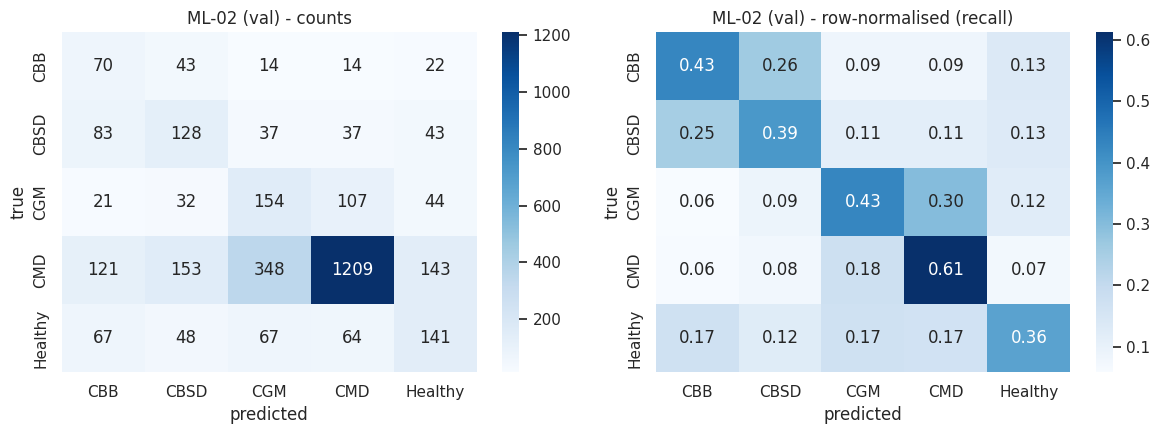

              precision    recall  f1-score   support

         CBB      0.193     0.429     0.267       163
        CBSD      0.317     0.390     0.350       328
         CGM      0.248     0.430     0.315       358
         CMD      0.845     0.612     0.710      1974
     Healthy      0.359     0.364     0.362       387

    accuracy                          0.530      3210
   macro avg      0.392     0.445     0.401      3210
weighted avg      0.633     0.530     0.565      3210



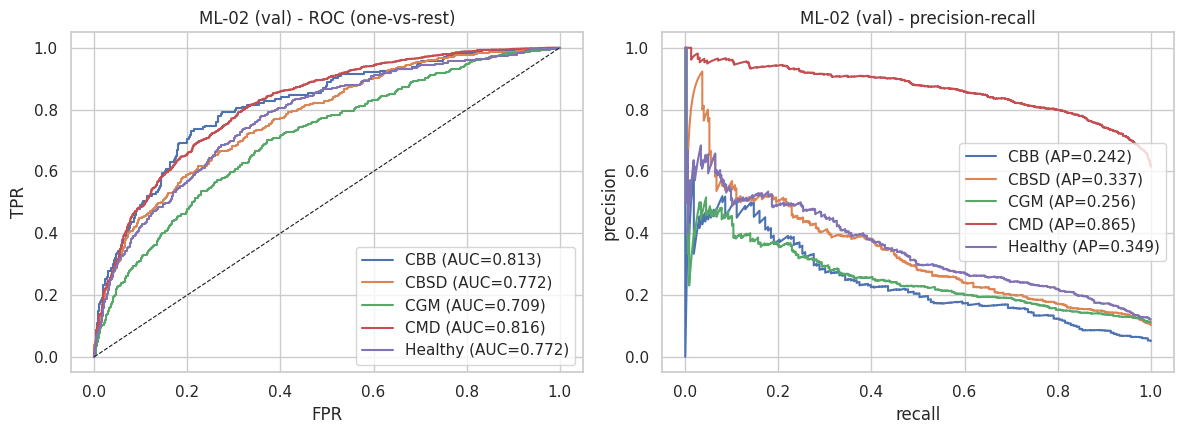

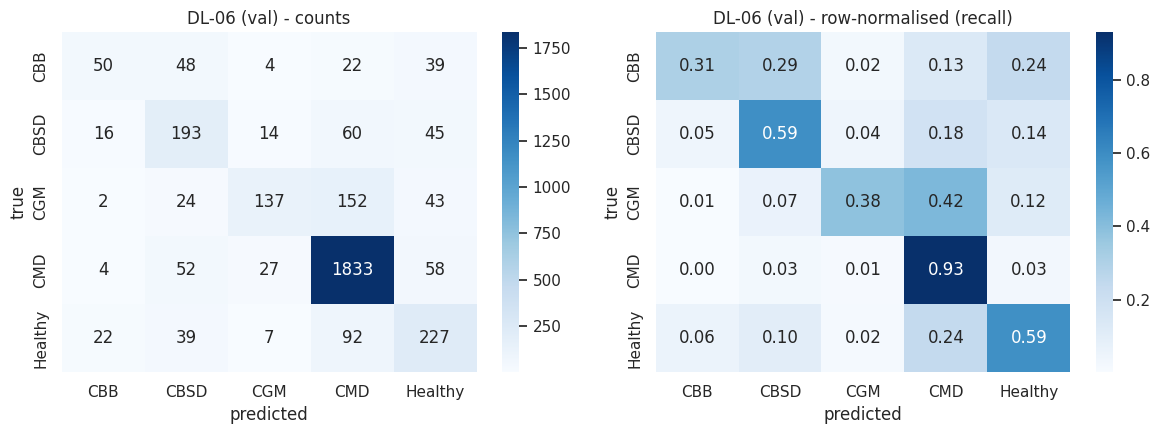

              precision    recall  f1-score   support

         CBB      0.532     0.307     0.389       163
        CBSD      0.542     0.588     0.564       328
         CGM      0.725     0.383     0.501       358
         CMD      0.849     0.929     0.887      1974
     Healthy      0.551     0.587     0.568       387

    accuracy                          0.760      3210
   macro avg      0.640     0.559     0.582      3210
weighted avg      0.752     0.760     0.747      3210



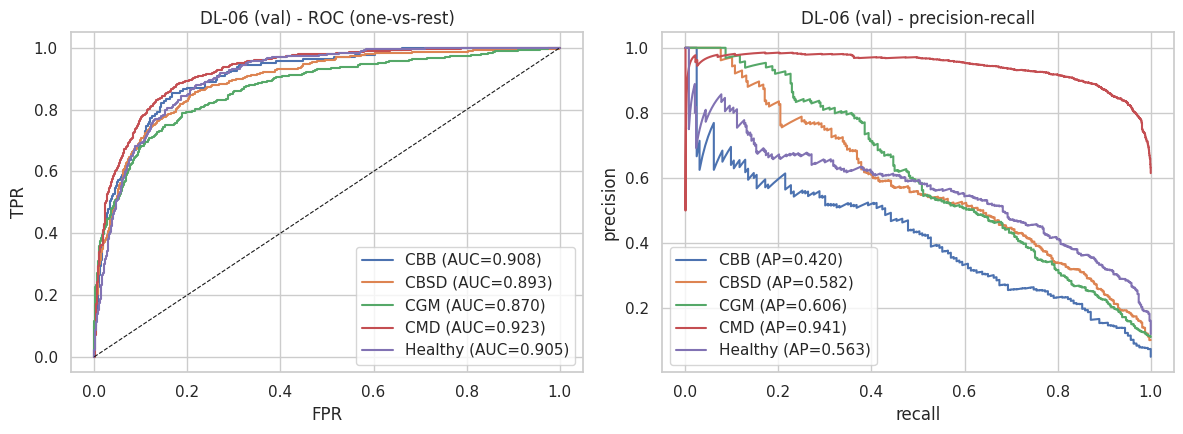

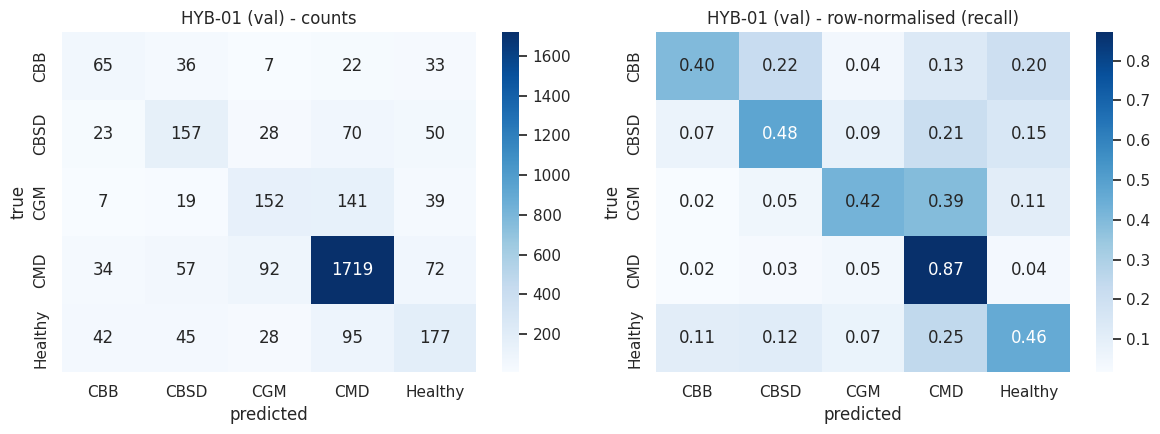

              precision    recall  f1-score   support

         CBB      0.380     0.399     0.389       163
        CBSD      0.500     0.479     0.489       328
         CGM      0.495     0.425     0.457       358
         CMD      0.840     0.871     0.855      1974
     Healthy      0.477     0.457     0.467       387

    accuracy                          0.707      3210
   macro avg      0.538     0.526     0.531      3210
weighted avg      0.700     0.707     0.703      3210



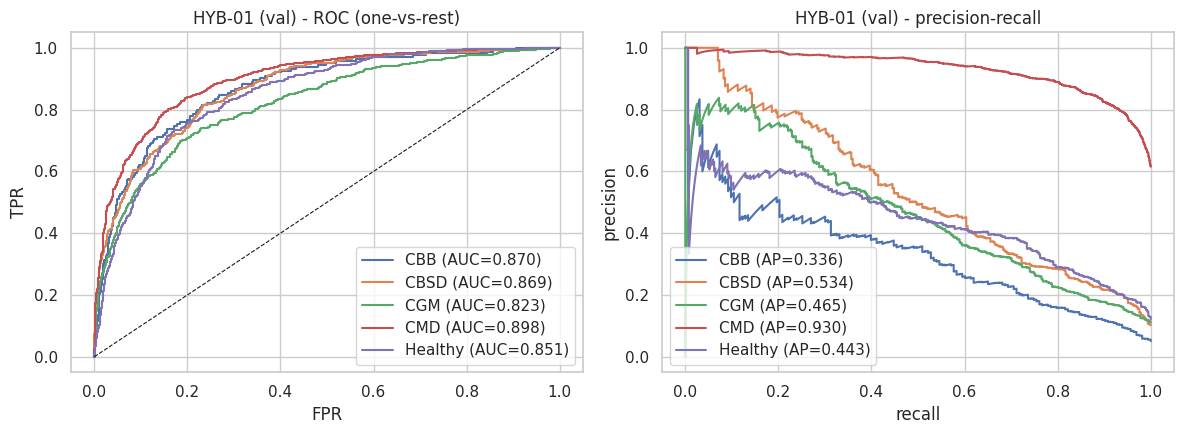

In [ ]:
def predict_split(exp_id, split):
    key = (exp_id, split)
    if key not in PROBA_CACHE:
        if exp_id in MODELS_DL: PROBA_CACHE[key] = predict_paths(MODELS_DL[exp_id], PATHS[split], Y[split])
        else:
            model, fs = MODELS_ML[exp_id]; PROBA_CACHE[key] = model.predict_proba(FM[fs][split])
    return PROBA_CACHE[key]

def best_of(paradigm):
    r = results[results.paradigm == paradigm]
    return r.sort_values("val_macro_f1").iloc[-1]["exp_id"] if len(r) else None

best_ml_id, best_dl_id, best_hyb_id = best_of("Traditional ML"), best_of("Deep Learning"), best_of("Hybrid")
selected = [i for i in (best_ml_id, best_dl_id, best_hyb_id) if i]
print("Selected on validation macro-F1:", dict(zip(["traditional", "deep", "hybrid"], [best_ml_id, best_dl_id, best_hyb_id])))

def plot_confusions(y_true, proba, title):
    pred = proba.argmax(1); cm = confusion_matrix(y_true, pred, labels=range(N_CLASSES))
    fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax[0]); ax[0].set_title(f"{title} - counts")
    sns.heatmap(cm / cm.sum(1, keepdims=True), annot=True, fmt=".2f", cmap="Blues", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax[1]); ax[1].set_title(f"{title} - row-normalised (recall)")
    for a_ in ax: a_.set_xlabel("predicted"); a_.set_ylabel("true")
    plt.tight_layout(); plt.show()
    print(classification_report(y_true, pred, target_names=CLASS_NAMES, digits=3, zero_division=0))
    return cm

def plot_roc_pr(y_true, proba, title):
    y_bin = label_binarize(y_true, classes=list(range(N_CLASSES)))
    fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
    for i, c in enumerate(CLASS_NAMES):
        fpr, tpr, _ = roc_curve(y_bin[:, i], proba[:, i]); ax[0].plot(fpr, tpr, label=f"{c} (AUC={auc(fpr, tpr):.3f})")
        p, r, _ = precision_recall_curve(y_bin[:, i], proba[:, i]); ax[1].plot(r, p, label=f"{c} (AP={average_precision_score(y_bin[:, i], proba[:, i]):.3f})")
    ax[0].plot([0, 1], [0, 1], "k--", lw=0.8); ax[0].set_title(f"{title} - ROC (one-vs-rest)"); ax[0].set_xlabel("FPR"); ax[0].set_ylabel("TPR"); ax[0].legend()
    ax[1].set_title(f"{title} - precision-recall"); ax[1].set_xlabel("recall"); ax[1].set_ylabel("precision"); ax[1].legend()
    plt.tight_layout(); plt.show()

CMS = {}
for k in selected:
    p = predict_split(k, "va"); CMS[k] = plot_confusions(y_va, p, f"{k} (val)"); plot_roc_pr(y_va, p, f"{k} (val)")

_Interpretation (own words):_ which classes are systematically confused and why (e.g. CBSD vs CMD vs Healthy, whose symptoms and field-photo appearance overlap); how recall for the minority classes (CBB, CBSD) compares across paradigms; what the ROC vs precision–recall curves say when one class is 61 % of the data; what a missed diseased plant costs a farmer compared with a false alarm.

**Facts from the validation outputs above (use them in your own interpretation; update if you rerun).** Per-class recall / precision:

| Class | ML-02 (traditional) | DL-06 (deep) | HYB-01 (hybrid) |
|---|---|---|---|
| CBB | 0.429 / 0.193 | 0.307 / 0.532 | 0.399 / 0.380 |
| CBSD | 0.390 / 0.317 | 0.588 / 0.542 | 0.479 / 0.500 |
| CGM | 0.430 / 0.248 | 0.383 / 0.725 | 0.425 / 0.495 |
| CMD | 0.612 / 0.845 | 0.929 / 0.849 | 0.871 / 0.840 |
| Healthy | 0.364 / 0.359 | 0.587 / 0.551 | 0.457 / 0.477 |

Questions to answer in your own words: which model finds CBB best, and at what cost in precision? Why does the class-weighted logistic regression have the lowest CMD recall? Which classes does DL-06 miss most often?

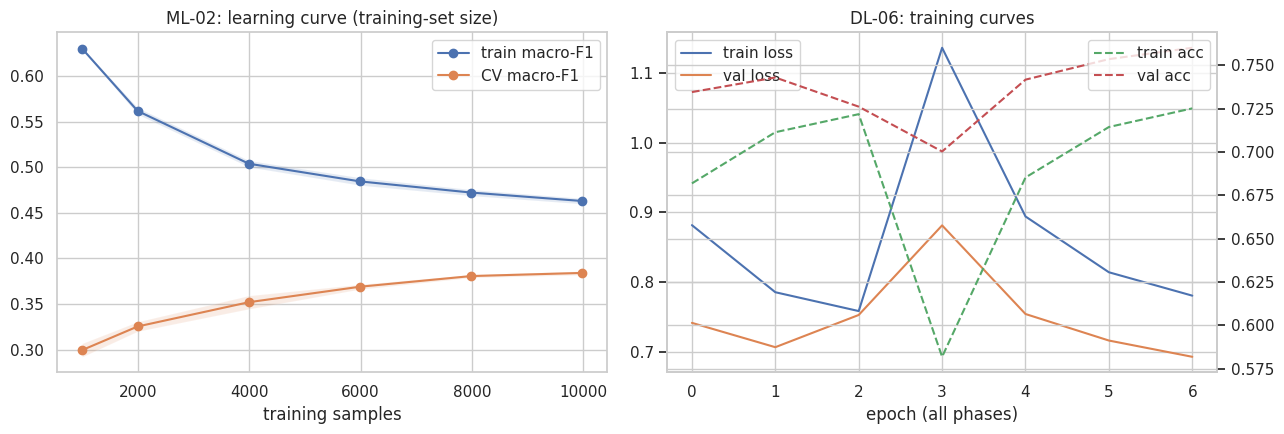

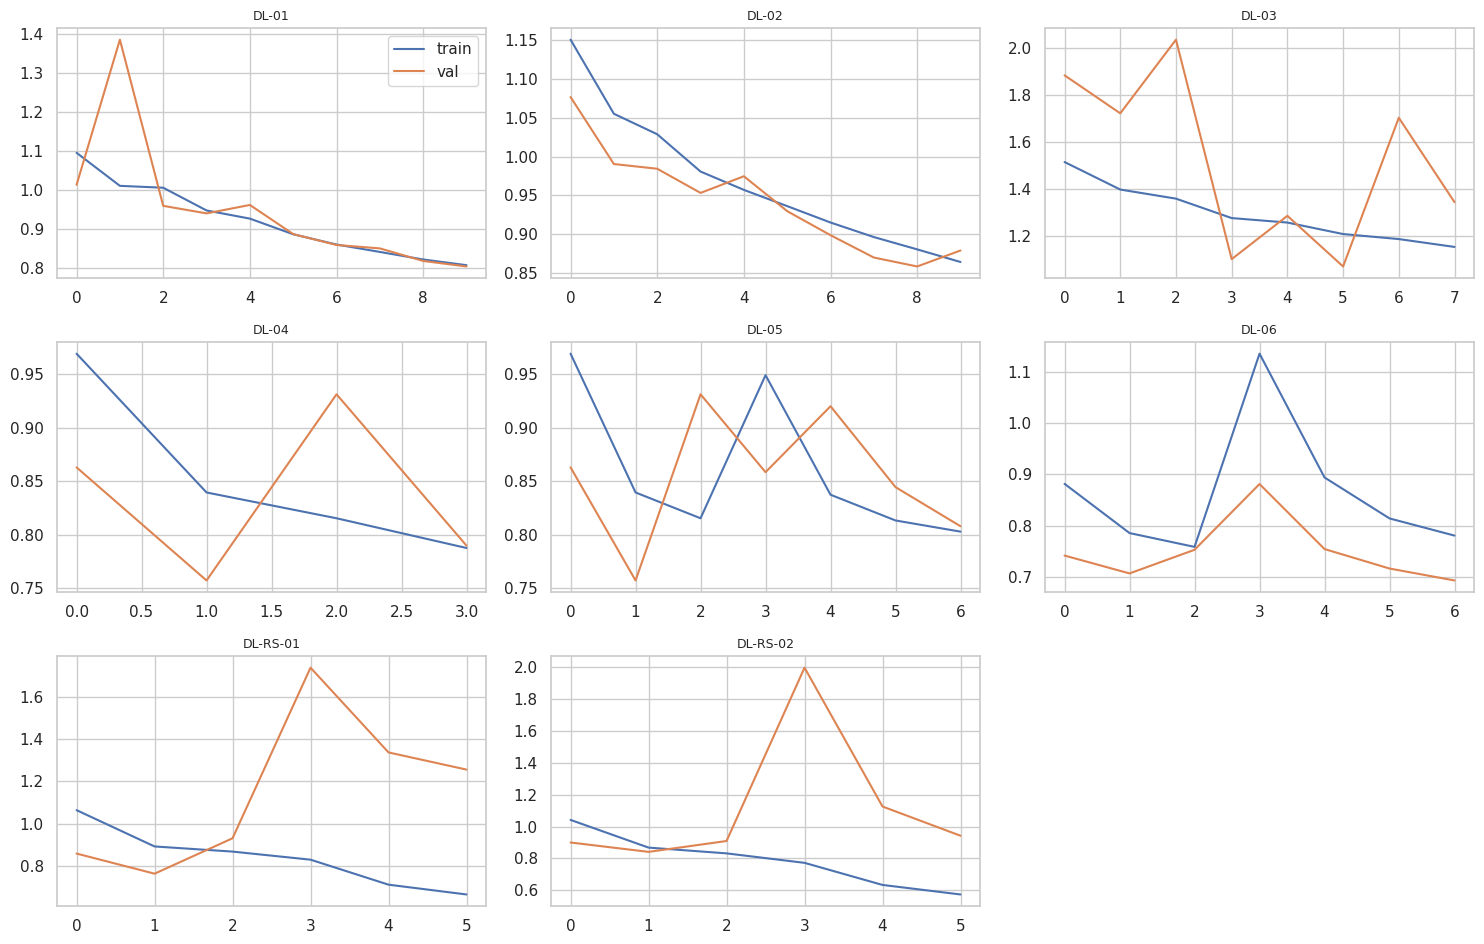

In [ ]:
# ---------------- learning curves ----------------
n_plots = 1 + (1 if best_dl_id else 0)
fig, ax = plt.subplots(1, n_plots, figsize=(6.5 * n_plots, 4.5), squeeze=False)
best_ml, best_fs = MODELS_ML[best_ml_id]
sizes = [0.3, 0.6, 1.0] if QUICK_RUN else [0.1, 0.2, 0.4, 0.6, 0.8, 1.0]
ts, tr_sc, va_sc = learning_curve(clone(best_ml), FM[best_fs]["tr"], y_tr, cv=StratifiedKFold(3, shuffle=True, random_state=SEED),
                                  train_sizes=sizes, scoring="f1_macro", n_jobs=-1)
ax[0, 0].plot(ts, tr_sc.mean(1), "o-", label="train macro-F1"); ax[0, 0].plot(ts, va_sc.mean(1), "o-", label="CV macro-F1")
ax[0, 0].fill_between(ts, tr_sc.mean(1) - tr_sc.std(1), tr_sc.mean(1) + tr_sc.std(1), alpha=0.15)
ax[0, 0].fill_between(ts, va_sc.mean(1) - va_sc.std(1), va_sc.mean(1) + va_sc.std(1), alpha=0.15)
ax[0, 0].set_title(f"{best_ml_id}: learning curve (training-set size)"); ax[0, 0].set_xlabel("training samples"); ax[0, 0].legend()
if best_dl_id:
    h = DL_HISTORIES[best_dl_id]
    ax[0, 1].plot(h["loss"], label="train loss"); ax[0, 1].plot(h["val_loss"], label="val loss"); ax[0, 1].set_xlabel("epoch (all phases)")
    ax2 = ax[0, 1].twinx(); ax2.plot(h["accuracy"], "--", color="C2", label="train acc"); ax2.plot(h["val_accuracy"], "--", color="C3", label="val acc")
    ax[0, 1].set_title(f"{best_dl_id}: training curves"); ax[0, 1].legend(loc="upper left"); ax2.legend(loc="upper right")
plt.tight_layout(); plt.show()

# training curves of every DL run for the report appendix / comparison
if DL_HISTORIES:
    cols = 3; rows = int(np.ceil(len(DL_HISTORIES) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(15, 3.2 * rows), squeeze=False)
    for a_, (k, h) in zip(axes.flat, DL_HISTORIES.items()):
        a_.plot(h["loss"], label="train"); a_.plot(h["val_loss"], label="val"); a_.set_title(k, fontsize=9)
    for a_ in list(axes.flat)[len(DL_HISTORIES):]: a_.axis("off")
    axes[0, 0].legend(); plt.tight_layout(); plt.show()

In [ ]:
# ---------------- bias-variance (Domingos 0-1 loss decomposition via bootstrap) on the validation set ----------------
def bias_variance_01(estimator, Xtr, ytr, Xev, yev, B=10, seed=SEED):
    rng_ = np.random.RandomState(seed); preds = np.zeros((B, len(yev)), dtype=int)
    for b in range(B):
        i = rng_.choice(len(ytr), len(ytr), replace=True); preds[b] = clone(estimator).fit(Xtr[i], ytr[i]).predict(Xev)
    main = np.array([np.bincount(preds[:, j], minlength=N_CLASSES).argmax() for j in range(len(yev))])
    return {"bias": (main != yev).mean(), "variance": (preds != main).mean(), "expected_0-1_loss": (preds != yev).mean()}

B = 3 if QUICK_RUN else 8
bv = bias_variance_01(best_ml, FM[best_fs]["tr"], y_tr, FM[best_fs]["va"], y_va, B=B)
print(f"Bias-variance decomposition for {best_ml_id} (0-1 loss, bootstrap B={B}):"); display(pd.Series(bv).round(4).to_frame("value"))
print("Largest train-validation gaps (variance / overfitting indicator):")
display(results[["exp_id", "model", "train_macro_f1", "val_macro_f1", "gap_macro_f1"]].round(4).sort_values("gap_macro_f1", ascending=False).head(8))

Bias-variance decomposition for ML-02 (0-1 loss, bootstrap B=8):


,value
bias,0.4735
variance,0.1788
expected_0-1_loss,0.4823


Largest train-validation gaps (variance / overfitting indicator):


,exp_id,model,train_macro_f1,val_macro_f1,gap_macro_f1
3,ML-04,Random Forest (all features),1.0000,0.2755,0.7245
2,ML-03,Random Forest (colour only),1.0000,0.2826,0.7174
5,ML-06,HistGradientBoosting,0.8725,0.3541,0.5185
7,ML-08,SVM RBF after PCA(32),0.6996,0.2381,0.4615
4,ML-05,Random Forest (tuned),0.8251,0.3894,0.4357
17,HYB-02,HistGB on CNN embeddings,0.9589,0.5252,0.4337
6,ML-07,HistGradientBoosting (tuned),0.7826,0.3818,0.4008
16,HYB-01,LogReg on CNN embeddings,0.7766,0.5315,0.2451


_Interpretation (own words):_ use the learning curves (is the validation curve still rising, so would more data help? is there a persistent train–validation gap?), the bias/variance numbers and the gap table to diagnose under- vs over-fitting for the classical models, and the DL curves (where did validation loss turn upward, and which regularisation delayed it?).

**Facts from the outputs above (use them in your own interpretation; update if you rerun).**

* Bias–variance for ML-02 (bootstrap B = 8, 0-1 loss on validation): bias 0.4735, variance 0.1788, expected loss 0.4823.
* Train vs validation macro-F1 (largest gaps): ML-04 1.000 vs 0.2755 (gap 0.7245); ML-03 1.000 vs 0.2826 (0.7174); ML-06 0.8725 vs 0.3541 (0.5185); ML-08 0.6996 vs 0.2381 (0.4615); ML-05 0.8251 vs 0.3894 (0.4357); HYB-02 0.9589 vs 0.5252 (0.4337); ML-07 0.7826 vs 0.3818 (0.4008); HYB-01 0.7766 vs 0.5315 (0.2451).

Questions to answer in your own words: is ML-02 limited mainly by bias or by variance, and what does that say about a linear model on these features? Which models overfit most, and what reduced the gap (compare ML-04 with ML-05)? For the learning curves, point to the epoch or training size where the validation line flattens or turns up.

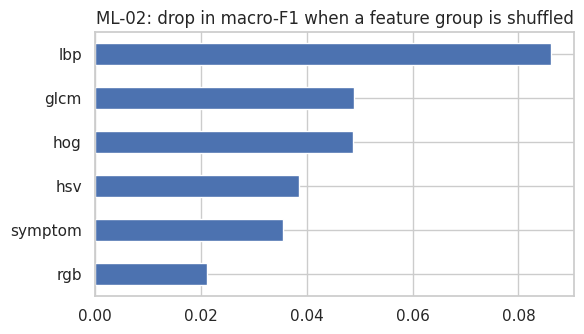

DL-06: 770 misclassified of 3210 validation images


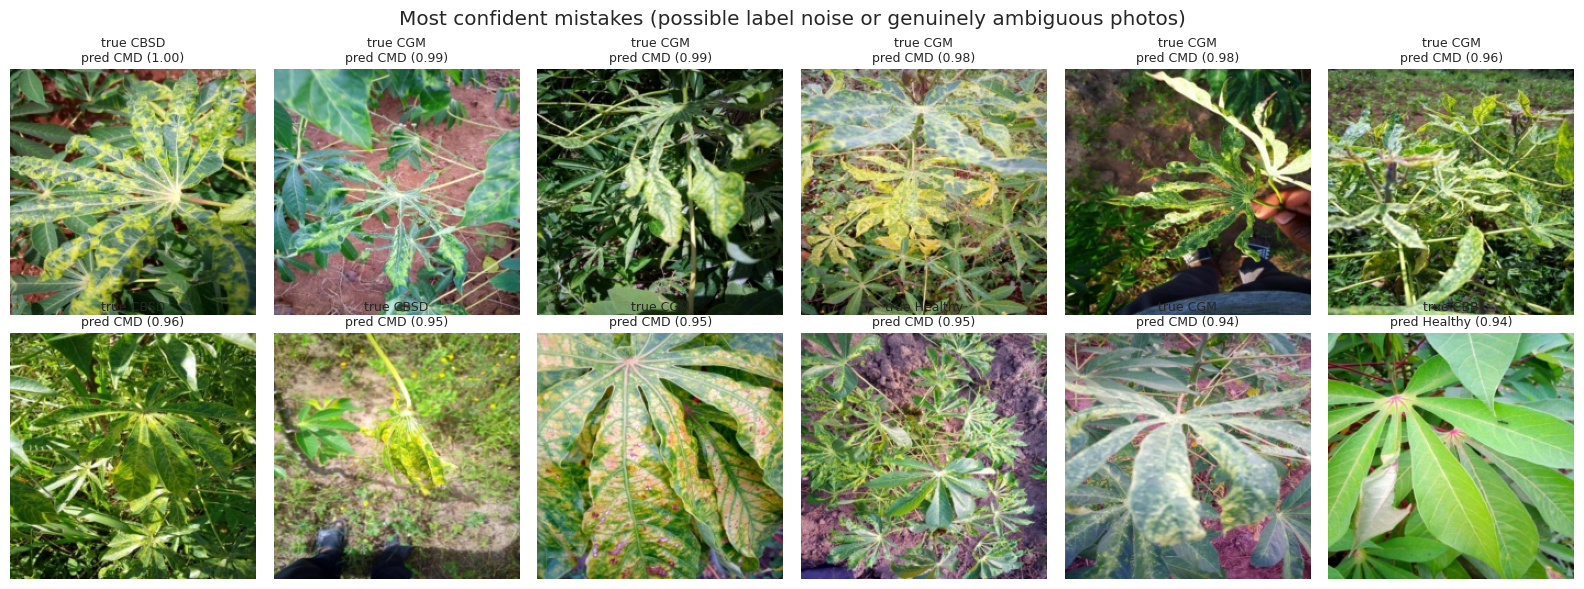


Error rate by hsv_v_mean tercile:


,error_rate,size
bin,,
low,0.264,1070
mid,0.236,1070
high,0.219,1070



Error rate by symptom_frac_green tercile:


,error_rate,size
bin,,
low,0.268,1070
mid,0.243,1070
high,0.208,1070



Most frequent confusions (count, true -> predicted): [(152, 'CGM', 'CMD'), (92, 'Healthy', 'CMD'), (60, 'CBSD', 'CMD')]


In [ ]:
# ---------------- feature-group importance for the best traditional model (permute whole groups on val) ----------------
if best_fs in ("color", "all"):
    cols_used = FEAT_COLS[best_fs]; Xv = FM[best_fs]["va"]; base_f1 = f1_score(y_va, best_ml.predict(Xv), average="macro")
    rng_ = np.random.RandomState(SEED); imp = {}
    for g, gcols in FEATURE_GROUPS.items():
        ci = [cols_used.index(c) for c in gcols if c in cols_used]
        if not ci: continue
        drops = []
        for _ in range(3 if QUICK_RUN else 5):
            Xp = Xv.copy(); perm = rng_.permutation(len(Xp)); Xp[:, ci] = Xp[perm][:, ci]
            drops.append(base_f1 - f1_score(y_va, best_ml.predict(Xp), average="macro"))
        imp[g] = np.mean(drops)
    pd.Series(imp).sort_values().plot.barh(figsize=(6, 3.5), title=f"{best_ml_id}: drop in macro-F1 when a feature group is shuffled")
    plt.tight_layout(); plt.show()

# ---------------- image-level error analysis for the best deep model ----------------
if best_dl_id:
    pv = predict_split(best_dl_id, "va"); pred = pv.argmax(1); wrong = np.where(pred != y_va)[0]
    print(f"{best_dl_id}: {len(wrong)} misclassified of {len(y_va)} validation images")
    order = wrong[np.argsort(-pv[wrong].max(1))][:12]          # most confident mistakes first
    fig, axes = plt.subplots(2, 6, figsize=(16, 6))
    for a_, i in zip(axes.flat, order):
        a_.imshow(Image.open(PATHS["va"][i])); a_.axis("off")
        a_.set_title(f"true {CLASS_NAMES[y_va[i]]}\npred {CLASS_NAMES[pred[i]]} ({pv[i].max():.2f})", fontsize=9)
    plt.suptitle("Most confident mistakes (possible label noise or genuinely ambiguous photos)"); plt.tight_layout(); plt.show()

    fv = feats.iloc[va_idx].reset_index(drop=True).assign(wrong=(pred != y_va).astype(int))
    for col in ["hsv_v_mean", "symptom_frac_green"]:
        fv["bin"] = pd.qcut(fv[col], 3, labels=["low", "mid", "high"])
        print(f"\nError rate by {col} tercile:"); display(fv.groupby("bin")["wrong"].agg(["mean", "size"]).round(3).rename(columns={"mean": "error_rate"}))
    cm = CMS[best_dl_id].astype(float); np.fill_diagonal(cm, 0)
    pairs = sorted(((cm[i, j], CLASS_NAMES[i], CLASS_NAMES[j]) for i in range(N_CLASSES) for j in range(N_CLASSES) if i != j), reverse=True)[:3]
    print("\nMost frequent confusions (count, true -> predicted):", [(int(n), a_, b_) for n, a_, b_ in pairs])

_Interpretation (own words):_ what the confident mistakes look like (mislabelled? several leaves? blurred?), whether brightness or leaf coverage correlates with errors, which feature groups carry the classical model, and 3–4 concrete justified next steps (e.g. stronger augmentation / test-time augmentation, focal loss or oversampling for CBB/CBSD, larger backbone, Grad-CAM to inspect what the network looks at, label-noise-robust training, on-device deployment with TFLite).

**Facts from the outputs above (use them in your own interpretation; update if you rerun).**

* DL-06 misclassified 770 of 3,210 validation images (24.0 %).
* Error rate by brightness tercile (`hsv_v_mean`): low 0.264, mid 0.236, high 0.219. By green-pixel fraction tercile: low 0.268, mid 0.243, high 0.208.
* Most frequent confusions (count, true → predicted): CGM → CMD 152, Healthy → CMD 92, CBSD → CMD 60. All three confusions are predictions of the majority class, CMD.

Questions to answer in your own words: why might dark or low-green photos be harder? Why does the majority class absorb the errors? Look at the confident-mistake gallery: do those photos look mislabelled, blurred, or ambiguous?

## 11. Final test-set evaluation and saved models
The test set is evaluated **once** for each selected model. Best models are saved to `artifacts/` for the Google Drive folder: the traditional pipeline (`.joblib`) and the deep model (`.keras`, legacy `.h5` and TensorFlow SavedModel).

,accuracy,balanced_acc,macro_f1,weighted_f1,macro_precision,macro_recall,roc_auc_ovr,pr_auc_macro
model,,,,,,,,
ML-02 (Logistic Regression (tuned)),0.5171,0.4332,0.3850,0.5526,0.3778,0.4332,0.7668,0.3812
DL-06 (EfficientNetB0 fine-tune (last 10)),0.7651,0.5666,0.5921,0.7530,0.6486,0.5666,0.9025,0.6253
HYB-01 (LogReg on CNN embeddings),0.7143,0.5160,0.5290,0.7065,0.5450,0.5160,0.8669,0.5453


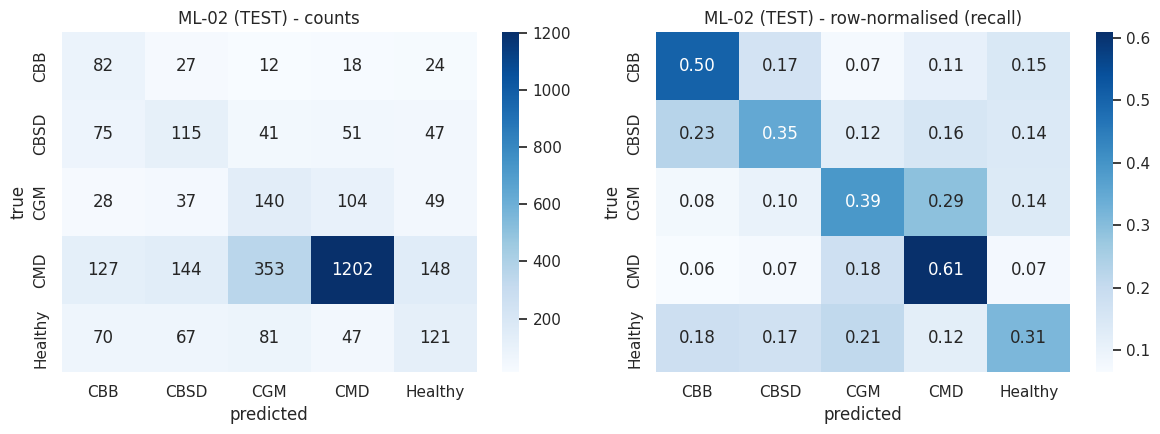

              precision    recall  f1-score   support

         CBB      0.215     0.503     0.301       163
        CBSD      0.295     0.350     0.320       329
         CGM      0.223     0.391     0.284       358
         CMD      0.845     0.609     0.708      1974
     Healthy      0.311     0.313     0.312       386

    accuracy                          0.517      3210
   macro avg      0.378     0.433     0.385      3210
weighted avg      0.623     0.517     0.553      3210



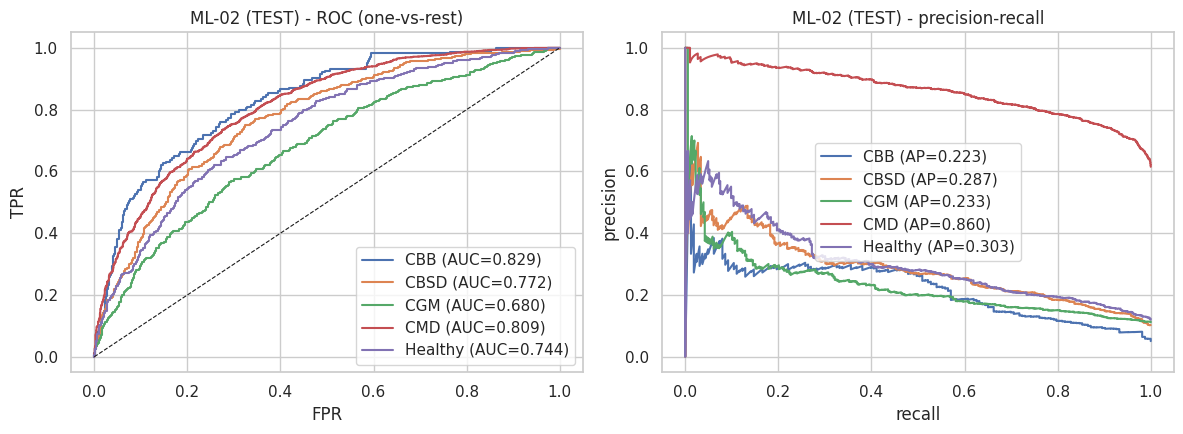

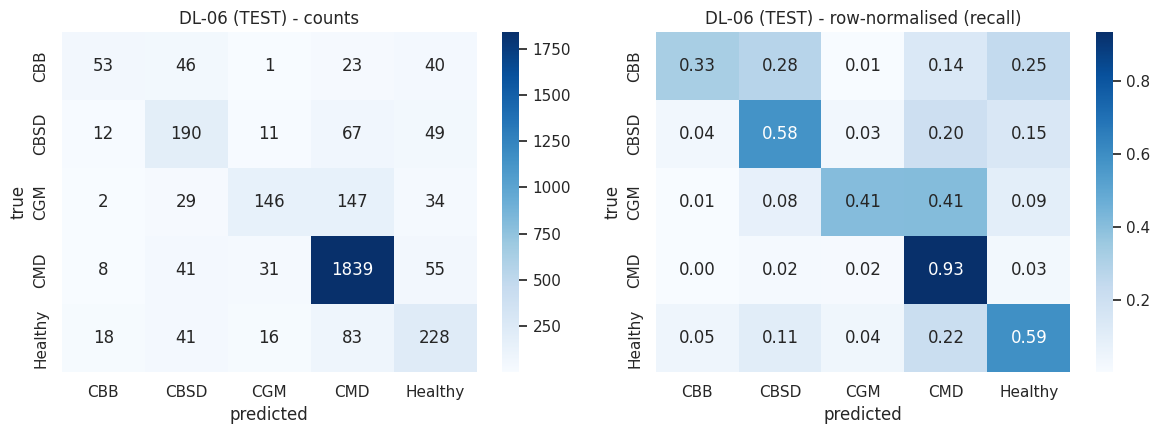

              precision    recall  f1-score   support

         CBB      0.570     0.325     0.414       163
        CBSD      0.548     0.578     0.562       329
         CGM      0.712     0.408     0.519       358
         CMD      0.852     0.932     0.890      1974
     Healthy      0.562     0.591     0.576       386

    accuracy                          0.765      3210
   macro avg      0.649     0.567     0.592      3210
weighted avg      0.756     0.765     0.753      3210



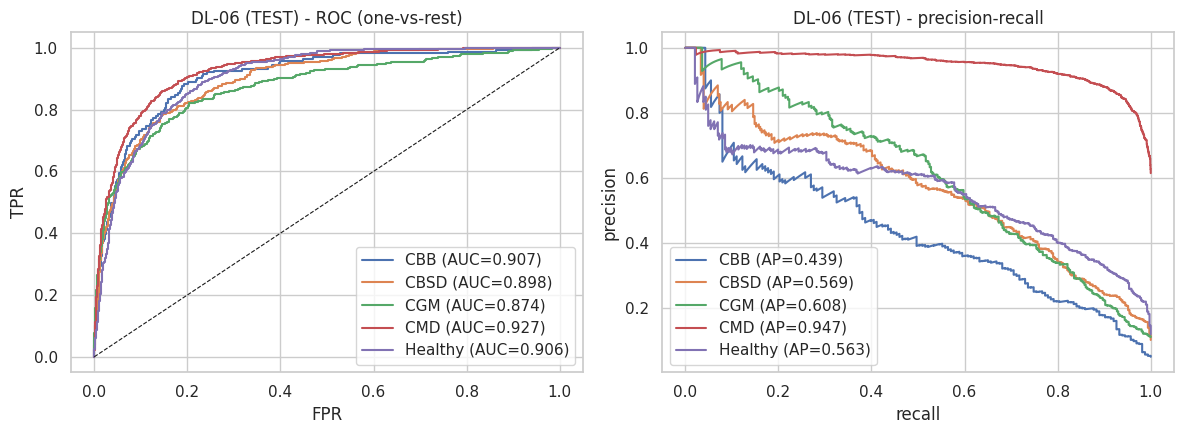

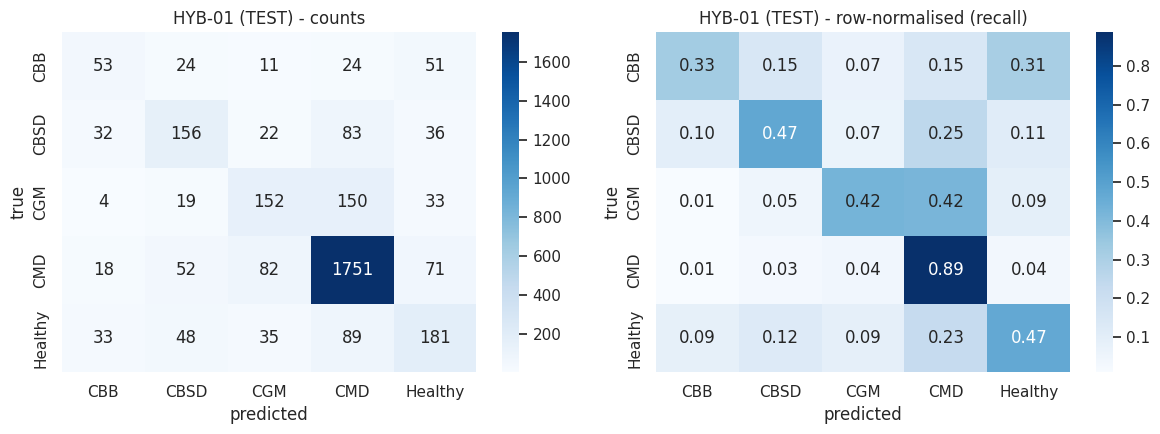

              precision    recall  f1-score   support

         CBB      0.379     0.325     0.350       163
        CBSD      0.522     0.474     0.497       329
         CGM      0.503     0.425     0.461       358
         CMD      0.835     0.887     0.860      1974
     Healthy      0.487     0.469     0.478       386

    accuracy                          0.714      3210
   macro avg      0.545     0.516     0.529      3210
weighted avg      0.701     0.714     0.706      3210



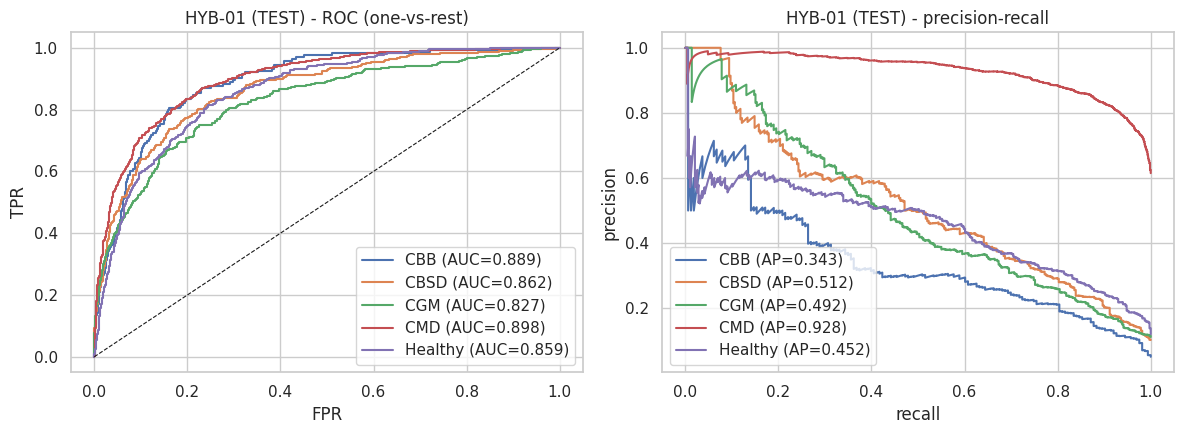

In [ ]:
final_rows, name_of = [], results.set_index("exp_id")["model"]
for k in selected:
    final_rows.append({"model": f"{k} ({name_of[k]})", **evaluate_probs(y_te, predict_split(k, "te"))})
final = pd.DataFrame(final_rows).set_index("model"); final.to_csv(ARTIFACT_DIR / "final_test_results.csv")
display(final.round(4))
for k in selected:
    p = predict_split(k, "te"); plot_confusions(y_te, p, f"{k} (TEST)"); plot_roc_pr(y_te, p, f"{k} (TEST)")

In [ ]:
joblib.dump(best_ml, ARTIFACT_DIR / "best_traditional_model.joblib")
print("Saved", ARTIFACT_DIR / "best_traditional_model.joblib", "(uses feature set:", best_fs + ")")
if best_dl_id:
    m = MODELS_DL[best_dl_id]
    m.save(str(ARTIFACT_DIR / "best_dl_model.keras"))
    try: m.save(str(ARTIFACT_DIR / "best_dl_model.h5"))
    except Exception as e: print("h5 save skipped:", e)
    try: m.export(str(ARTIFACT_DIR / "best_dl_savedmodel"))
    except Exception as e: print("SavedModel export skipped:", e)
    print("Saved deep model files to", ARTIFACT_DIR)

Saved artifacts/best_traditional_model.joblib (uses feature set: all)


Saved artifact at 'artifacts/best_dl_savedmodel'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='keras_tensor')
Output Type:
  TensorSpec(shape=(None, 5), dtype=tf.float32, name=None)
Captures:
  133494161744208: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133494161750160: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133494304554640: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133494304554256: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133493983875664: TensorSpec(shape=(1, 1, 1, 3), dtype=tf.float32, name=None)
  133493983874704: TensorSpec(shape=(1, 1, 1, 3), dtype=tf.float32, name=None)
  133494304552528: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133494304552720: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133494304552912: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133494304550224: TensorSpec(shape=(), dtype=tf.resourc

**Facts from the final test-set outputs above (use them in your own conclusion; update if you rerun).**

| Model | Accuracy | Balanced acc. | Macro-F1 | ROC-AUC | PR-AUC |
|---|---|---|---|---|---|
| ML-02 (traditional) | 0.5171 | 0.4332 | 0.3850 | 0.7668 | 0.3812 |
| DL-06 (deep) | 0.7651 | 0.5666 | 0.5921 | 0.9025 | 0.6253 |
| HYB-01 (hybrid) | 0.7143 | 0.5160 | 0.5290 | 0.8669 | 0.5453 |

Validation macro-F1 was 0.4006 (ML-02), 0.5819 (DL-06) and 0.5315 (HYB-01), so the test results are close to the validation results. Test recall by class (CBB / CBSD / CGM / CMD / Healthy): ML-02 0.503 / 0.350 / 0.391 / 0.609 / 0.313; DL-06 0.325 / 0.578 / 0.408 / 0.932 / 0.591; HYB-01 0.325 / 0.474 / 0.425 / 0.887 / 0.469.

## 12. Conclusions, limitations and future work
_Write in your own words (≈150–250 words):_
1. **Headline result:** best traditional vs best deep vs hybrid model on the held-out test set; which you would deploy and why (accuracy, minority-class recall, model size, inference cost on a phone).
2. **What mattered most:** engineered symptom/texture features vs colour alone (ML-03 vs ML-04), transfer learning vs scratch CNN, augmentation, class weights, fine-tuning depth.
3. **Limitations:** class imbalance, label noise in field photos, a single source region (Uganda), fixed 224-px resolution, validation-based selection on a single split.
4. **Future work:** Grad-CAM explainability, test-time augmentation, noise-robust losses, TFLite deployment on low-end phones, evaluation on photos from Rwanda.

**Ethics / deployment note:** a misdiagnosis can lead a farmer to uproot healthy plants or ignore disease, so such a model should support, not replace, extension officers, and its minority-class performance must be reported honestly.

## References
_IEEE style, ≥ 10 scholarly sources in the report (not here). Dataset citation (verify details):_ E. Mwebaze, T. Gebru, A. Frome, S. Nsumba and J. Tusubira, "iCassava 2019 fine-grained visual categorization challenge," arXiv:1908.02900, 2019; and the Kaggle "Cassava Leaf Disease Classification" competition (Makerere AI Lab and NaCRRI), 2020.

## Reproducibility checklist
- [ ] `SEED = 42`; `QUICK_RUN = False` for reported runs
- [ ] `requirements.txt` committed; raw data and `data/` **not** committed
- [ ] Notebook runs top-to-bottom; `artifacts/experiment_table.csv` matches the report's table
- [ ] W&B offline runs and/or TensorBoard logs available
- [ ] Raw data zip + best models uploaded to Drive ("anyone with the link can view"); GitHub, Drive and video links on page 1 of the report